In [4]:




import os
import glob
import pandas as pd

# 源数据目录
SRC_DIR = r"C:\Users\greenlandProject\ERA5LAND\dataverse_files\month"

# 目标年份
TARGET_YEAR = 2025

# 输出到桌面
OUTPUT_DIR = r"C:\Users\11823\Desktop"
OUTPUT_FILE = os.path.join(OUTPUT_DIR, f"albedo_{TARGET_YEAR}_all_stations.csv")


def extract_station_name(filename: str) -> str:
    base = os.path.basename(filename)
    name, _ = os.path.splitext(base)
    lower = name.lower()
    key = "_month"
    pos = lower.find(key)
    return name[:pos] if pos != -1 else name


def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    all_rows = []

    csv_files = glob.glob(os.path.join(SRC_DIR, "*.csv"))
    if not csv_files:
        print(f"目录内未发现csv文件：{SRC_DIR}")
        return

    for fp in csv_files:
        station = extract_station_name(fp)

        try:
            df = pd.read_csv(fp)
        except Exception as e:
            print(f"文件读取失败：{fp}，原因：{e}")
            continue

        if "time" not in df.columns:
            print(f"文件缺少time列，已跳过：{fp}")
            continue
        if "albedo" not in df.columns:
            print(f"文件缺少albedo列，已跳过：{fp}")
            continue

        # 解析时间，去掉已弃用的 infer_datetime_format 参数
        dt = pd.to_datetime(df["time"], errors="coerce")
        mask = dt.dt.year == TARGET_YEAR

        # 过滤目标年份
        df_year = df.loc[mask, ["albedo"]].copy()
        df_year["year"] = TARGET_YEAR
        df_year["month"] = dt.loc[mask].dt.month
        df_year.insert(0, "station", station)

        # 仅保留四列且顺序固定
        df_year = df_year[["station", "year", "month", "albedo"]]

        count_vals = len(df_year)
        all_rows.append(df_year)

        print(f"站点{station}{TARGET_YEAR}年有{count_vals}个值，已保存")

    if not all_rows:
        print(f"{TARGET_YEAR}年无任何站点数据，未生成汇总文件。")
        return

    result = pd.concat(all_rows, ignore_index=True)
    result.sort_values(by=["station", "year", "month"], inplace=True)

    result.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")
    print(f"汇总文件已生成：{OUTPUT_FILE}（共{len(result)}行）")


if __name__ == "__main__":
    main()

站点CEN2025年有9个值，已保存
站点CP12025年有9个值，已保存
站点DY22025年有9个值，已保存
站点EGP2025年有9个值，已保存
站点FRE2025年有9个值，已保存
站点HUM2025年有9个值，已保存
站点JAR2025年有9个值，已保存
站点KAN_B2025年有9个值，已保存
站点KAN_L2025年有9个值，已保存
站点KAN_M2025年有9个值，已保存
站点KAN_T2025年有9个值，已保存
站点KAN_U2025年有9个值，已保存
站点KPC_L2025年有9个值，已保存
站点KPC_U2025年有9个值，已保存
站点LYN_L2025年有9个值，已保存
站点LYN_T2025年有0个值，已保存
站点MIT2025年有9个值，已保存
站点NAE2025年有9个值，已保存
站点NAU2025年有9个值，已保存
站点NEM2025年有9个值，已保存
站点NSE2025年有9个值，已保存
站点NUK_B2025年有8个值，已保存
站点NUK_K2025年有9个值，已保存
站点NUK_L2025年有9个值，已保存
站点NUK_N2025年有0个值，已保存
站点NUK_U2025年有9个值，已保存
站点QAS_A2025年有0个值，已保存
站点QAS_L2025年有9个值，已保存
站点QAS_M2025年有4个值，已保存
站点QAS_U2025年有9个值，已保存
站点RED_L2025年有9个值，已保存
站点SCO_L2025年有9个值，已保存
站点SCO_U2025年有9个值，已保存
站点SDL2025年有9个值，已保存
站点SDM2025年有9个值，已保存
站点SER_B2025年有9个值，已保存
站点SWC2025年有9个值，已保存
站点TAS_A2025年有9个值，已保存
站点TAS_L2025年有9个值，已保存
站点TAS_U2025年有0个值，已保存
站点THU_L22025年有7个值，已保存
站点THU_L2025年有8个值，已保存
站点THU_U2025年有9个值，已保存
站点TUN2025年有9个值，已保存
站点UPE_L2025年有9个值，已保存
站点UPE_U2025年有9个值，已保存
站点WEG_B2025年有9个值，已保存
站点WEG_L2025年有9个值，已保存
站点ZAC_A2025年有7个值，已保存
站点

In [11]:
import pandas as pd
import xarray as xr

# 文件路径
file_csv = r"C:\Users\11823\Desktop\albedo_2025_all_stations.csv"
file_nc = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\merged_era5_snow_2025.nc"

# 1. 读取 CSV 和 NetCDF
df = pd.read_csv(file_csv)
ds = xr.open_dataset(file_nc)

# 2. 重命名 time -> lat（因为它其实是纬度）
ds = ds.rename({"time": "lat"})

# 3. 构造 valid_time（每月1号即可）
df['valid_time'] = pd.to_datetime(df[['year', 'month']].assign(day=1))

# 4. 获取所有变量名（12个）
variables = list(ds.data_vars)
print("✅ 将要提取的变量：", variables)

# 5. 遍历 CSV，提取最近邻气象变量
results = []
for idx, row in df.iterrows():
    point_data = ds.sel(
        valid_time=row['valid_time'],
        lat=row['latitude'],
        lon=row['longitude'],
        method="nearest"
    )
    values = {var: point_data[var].values.item() for var in variables}
    results.append(values)

# 6. 把结果合并到 df
df_vars = pd.DataFrame(results)
df_final = pd.concat([df, df_vars], axis=1)

# 7. 保存回原文件（覆盖保存）
df_final.to_csv(file_csv, index=False)

print("🎉 已完成：文件已更新，新增 12 列气象变量。")


✅ 将要提取的变量： ['t2m', 'asn', 'fal', 'slhf', 'str', 'ssrd', 'strd', 'u10', 'v10', 'sp', 'snowc', 'sde']
🎉 已完成：文件已更新，新增 12 列气象变量。


In [12]:
import pandas as pd
import numpy as np

def merge_altitude_data():
    """
    根据station列匹配，将merged_allfeature.csv中的altitude_last_valid列
    添加到albedo_2025_all_stations.csv中
    """
    
    try:
        # 读取两个CSV文件
        print("正在读取文件...")
        
        # 读取包含altitude_last_valid的文件
        df_altitude = pd.read_csv(r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv")
        print(f"merged_allfeature.csv: {df_altitude.shape[0]} 行, {df_altitude.shape[1]} 列")
        
        # 读取需要添加altitude列的文件
        df_albedo = pd.read_csv(r"C:\Users\11823\Desktop\albedo_2025_all_stations.csv")
        print(f"albedo_2025_all_stations.csv: {df_albedo.shape[0]} 行, {df_albedo.shape[1]} 列")
        
        # 检查必要的列是否存在
        if 'station' not in df_altitude.columns:
            print("错误: merged_allfeature.csv 中没有找到 'station' 列")
            return
        
        if 'station' not in df_albedo.columns:
            print("错误: albedo_2025_all_stations.csv 中没有找到 'station' 列")
            return
            
        if 'altitude_last_valid' not in df_altitude.columns:
            print("错误: merged_allfeature.csv 中没有找到 'altitude_last_valid' 列")
            return
        
        # 显示station列的基本信息
        print(f"\nmerged_allfeature.csv 中唯一station数量: {df_altitude['station'].nunique()}")
        print(f"albedo_2025_all_stations.csv 中唯一station数量: {df_albedo['station'].nunique()}")
        
        # 创建altitude数据的映射表（去重，每个station只保留一个altitude值）
        altitude_mapping = df_altitude[['station', 'altitude_last_valid']].drop_duplicates(subset=['station'])
        
        # 检查是否有station对应多个不同的altitude值
        station_altitude_counts = df_altitude.groupby('station')['altitude_last_valid'].nunique()
        multi_altitude_stations = station_altitude_counts[station_altitude_counts > 1]
        
        if len(multi_altitude_stations) > 0:
            print(f"\n警告: {len(multi_altitude_stations)} 个station有多个不同的altitude_last_valid值:")
            for station, count in multi_altitude_stations.head().items():
                altitudes = df_altitude[df_altitude['station'] == station]['altitude_last_valid'].unique()
                print(f"  Station {station}: {count} 个不同值 {altitudes}")
            print("  将使用每个station的第一个altitude值")
        
        # 执行左连接，根据station列匹配
        df_merged = df_albedo.merge(
            altitude_mapping, 
            on='station', 
            how='left'
        )
        
        # 检查匹配结果
        matched_stations = df_merged['altitude_last_valid'].notna().sum()
        total_stations = len(df_merged)
        
        print(f"\n匹配结果:")
        print(f"总记录数: {total_stations}")
        print(f"成功匹配altitude的记录数: {matched_stations}")
        print(f"未匹配到altitude的记录数: {total_stations - matched_stations}")
        print(f"匹配率: {matched_stations/total_stations*100:.1f}%")
        
        # 显示未匹配的station（如果数量不多的话）
        unmatched_stations = df_merged[df_merged['altitude_last_valid'].isna()]['station'].unique()
        if len(unmatched_stations) > 0 and len(unmatched_stations) <= 10:
            print(f"\n未匹配到altitude的station: {list(unmatched_stations)}")
        elif len(unmatched_stations) > 10:
            print(f"\n未匹配到altitude的station太多({len(unmatched_stations)}个)，不完全显示")
        
        # 保存合并后的文件
        output_path = r"C:\Users\11823\Desktop\albedo_2025_all_stations_with_altitude.csv"
        df_merged.to_csv(output_path, index=False)
        print(f"\n合并后的文件已保存到: {output_path}")
        print(f"最终文件: {df_merged.shape[0]} 行, {df_merged.shape[1]} 列")
        
        # 显示altitude列的统计信息
        if matched_stations > 0:
            altitude_stats = df_merged['altitude_last_valid'].describe()
            print(f"\naltitude_last_valid列统计信息:")
            print(altitude_stats)
        
        return df_merged
        
    except FileNotFoundError as e:
        print(f"文件未找到错误: {e}")
        print("请检查文件路径是否正确")
    except Exception as e:
        print(f"处理过程中出现错误: {e}")

# 执行函数
if __name__ == "__main__":
    result_df = merge_altitude_data()

正在读取文件...
merged_allfeature.csv: 4455 行, 17 列
albedo_2025_all_stations.csv: 412 行, 18 列

merged_allfeature.csv 中唯一station数量: 49
albedo_2025_all_stations.csv 中唯一station数量: 47

匹配结果:
总记录数: 412
成功匹配altitude的记录数: 395
未匹配到altitude的记录数: 17
匹配率: 95.9%

未匹配到altitude的station: ['NUK_B', 'SER_B']

合并后的文件已保存到: C:\Users\11823\Desktop\albedo_2025_all_stations_with_altitude.csv
最终文件: 412 行, 19 列

altitude_last_valid列统计信息:
count     395.000000
mean     1159.748785
std       799.079962
min        17.900000
25%       551.230000
50%       876.710000
75%      1920.390000
max      2897.530000
Name: altitude_last_valid, dtype: float64


In [14]:
import pandas as pd
import os

def process_albedo_file(file_path):
    """
    Reads a CSV file, rounds the longitude and latitude to one decimal place,
    and saves the modified data to a new file with "_0.1" appended to the name.

    Args:
        file_path (str): The full path to the input CSV file.
    """
    try:
        # 1. 检查文件路径是否存在
        if not os.path.exists(file_path):
            print(f"Error: The file at {file_path} does not exist.")
            return

        # 2. 读取CSV文件
        df = pd.read_csv(file_path)

        # 3. 检查文件是否包含 'longitude' 和 'latitude' 列
        if 'longitude' not in df.columns or 'latitude' not in df.columns:
            print("Error: The CSV file must contain 'longitude' and 'latitude' columns.")
            return

        # 4. 对经纬度列进行四舍五入，保留一位小数
        # 我们可以使用 .round() 方法
        df['longitude'] = df['longitude'].round(1)
        df['latitude'] = df['latitude'].round(1)

        # 5. 构建新文件的路径
        dir_name = os.path.dirname(file_path)
        base_name = os.path.basename(file_path)
        file_name, file_ext = os.path.splitext(base_name)
        new_file_path = os.path.join(dir_name, f"{file_name}_0.1{file_ext}")

        # 6. 保存修改后的数据到新文件
        df.to_csv(new_file_path, index=False)
        
        print(f"File processed successfully! The new file is saved at: {new_file_path}")

    except Exception as e:
        print(f"An error occurred: {e}")

# 调用函数，传入你的文件路径
# 请将下面的路径替换成你的实际文件路径
file_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations.csv"
process_albedo_file(file_path)

File processed successfully! The new file is saved at: C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1.csv


In [20]:
import pandas as pd
import numpy as np
import joblib
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
import os

# ========== 1. 路径 ==========
file_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1.csv"
model_dir = r"C:\Users\11823\era5land\saved_models_917"  # 你保存pkl文件的目录

# 需要的特征
input_features = [
    "longitude", "latitude", "altitude_last_valid",
    "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10",
    "snowc", "sde", "asn",
    "year", "month"
]

# ========== 2. 加载数据 ==========
df = pd.read_csv(file_path)

X_new = df[input_features].astype(float)
y_true = df["st_albedo"].astype(float)  # 真值列

# ========== 3. 加载模型 ==========
base_models = {
    'RF': joblib.load(os.path.join(model_dir, "RF_917.pkl")),
    'XGB': joblib.load(os.path.join(model_dir, "XGB_917.pkl")),
    'GBDT': joblib.load(os.path.join(model_dir, "GBDT_917.pkl")),
    'LGBM': joblib.load(os.path.join(model_dir, "LGBM_917.pkl")),
    'CatBoost': joblib.load(os.path.join(model_dir, "CatBoost_917.pkl")),
}
meta_model = joblib.load(os.path.join(model_dir, "meta_model_917.pkl"))

# ========== 4. 预测 ==========
# 先用每个基础模型预测
meta_features_new = np.column_stack([m.predict(X_new) for m in base_models.values()])

# 再用元模型融合
y_pred = meta_model.predict(meta_features_new)

# 存入DataFrame
df["albedo_pred"] = y_pred

# ========== 5. 计算统计量 ==========
r2 = r2_score(y_true, y_pred)
r, _ = pearsonr(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
bias = np.mean(y_pred - y_true)

print("\n========== 2025 Prediction Evaluation ==========")
print(f"R²: {r2:.6f}")
print(f"Pearson R: {r:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MSE: {mse:.6f}")
print(f"Bias: {bias:.6f}")

# ========== 6. 保存结果 ==========
out_path = file_path.replace(".csv", "_with_pred_917.csv")
df.to_csv(out_path, index=False)
print(f"\n✅ 预测结果已保存到: {out_path}")



========== 2025 Prediction Evaluation ==========
R²: 0.808971
Pearson R: 0.902202
RMSE: 0.092454
MSE: 0.008548
Bias: 0.007030

✅ 预测结果已保存到: C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917.csv


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr, spearmanr
import os

# ===== 1) 配置：替换为你的结果文件路径（需包含 st_albedo 与 albedo_pred 两列）=====
file_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917.csv"

# ===== 2) 读取与清洗 =====
df = pd.read_csv(file_path)
if not {"st_albedo", "albedo_pred"}.issubset(df.columns):
    raise ValueError("CSV 必须包含列：'st_albedo' 和 'albedo_pred'。")

# 丢掉无效值
df = df.copy()
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=["st_albedo", "albedo_pred"])
y_true = df["st_albedo"].astype(float).values
y_pred = df["albedo_pred"].astype(float).values

# ===== 3) 计算指标 =====
def lin_ccc(x, y):
    """Lin's Concordance Correlation Coefficient"""
    mu_x, mu_y = np.mean(x), np.mean(y)
    var_x, var_y = np.var(x, ddof=1), np.var(y, ddof=1)
    sd_x, sd_y = np.sqrt(var_x), np.sqrt(var_y)
    r, _ = pearsonr(x, y)
    return (2 * r * sd_x * sd_y) / (var_x + var_y + (mu_x - mu_y) ** 2)

r2 = r2_score(y_true, y_pred)
r, _ = pearsonr(y_true, y_pred)
rho, _ = spearmanr(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
bias = np.mean(y_pred - y_true)                          # MBE
nmbe_pct = bias / np.mean(y_true) * 100                  # 归一化偏差（相对均值）
nrmse_pct = rmse / np.mean(y_true) * 100                 # 归一化RMSE（相对均值）
ccc = lin_ccc(y_true, y_pred)

# 简单的OLS拟合（y_pred ~ a * y_true + b）
a, b = np.polyfit(y_true, y_pred, 1)

metrics = {
    "N": [len(y_true)],
    "R2": [r2],
    "Pearson_R": [r],
    "Spearman_rho": [rho],
    "RMSE": [rmse],
    "MAE": [mae],
    "MBE_Bias": [bias],
    "NMBE_%": [nmbe_pct],
    "NRMSE_%": [nrmse_pct],
    "Lin_CCC": [ccc],
    "OLS_slope": [a],
    "OLS_intercept": [b],
    "y_true_mean": [np.mean(y_true)],
    "y_pred_mean": [np.mean(y_pred)],
}

metrics_df = pd.DataFrame(metrics)
print("\n========== Metrics (2025) ==========")
print(metrics_df.to_string(index=False))

# ===== 4) 保存指标CSV =====
out_dir = os.path.dirname(file_path)
metrics_path = os.path.join(out_dir, os.path.basename(file_path).replace(".csv", "_metrics_917.csv"))
metrics_df.to_csv(metrics_path, index=False)
print(f"\n✅ 指标已保存: {metrics_path}")

# ===== 5) 散点图（带 1:1 线 + 回归线）=====
plt.figure(figsize=(7, 7))
plt.scatter(y_true, y_pred, s=12, alpha=0.6)

# 1:1 参考线
xy_min = float(np.nanmin([y_true.min(), y_pred.min()]))
xy_max = float(np.nanmax([y_true.max(), y_pred.max()]))
plt.plot([xy_min, xy_max], [xy_min, xy_max], linestyle="--")

# 回归线
x_line = np.linspace(xy_min, xy_max, 100)
y_line = a * x_line + b
plt.plot(x_line, y_line, linestyle="-")

plt.xlabel("st_albedo (Truth)")
plt.ylabel("albedo_pred (Model)")
plt.title("st_albedo vs albedo_pred (with 1:1 and OLS fit)")

# 在图上标注关键指标
txt = (
    f"N={len(y_true)}\n"
    f"R²={r2:.3f}\n"
    f"R={r:.3f}, ρ={rho:.3f}\n"
    f"RMSE={rmse:.3f}, MAE={mae:.3f}\n"
    f"Bias={bias:.3f}\n"
    f"NMBE={nmbe_pct:.2f}%, NRMSE={nrmse_pct:.2f}%\n"
    f"CCC={ccc:.3f}\n"
    f"slope={a:.3f}, intercept={b:.3f}"
)
plt.gca().text(0.05, 0.95, txt, transform=plt.gca().transAxes, va="top", ha="left",
               bbox=dict(boxstyle="round", alpha=0.2))

plt.tight_layout()
fig_path = os.path.join(out_dir, os.path.basename(file_path).replace(".csv", "_scatter_917.png"))
plt.savefig(fig_path, dpi=200)
plt.close()
print(f"✅ 散点图已保存: {fig_path}")



========== Metrics (2025) ==========
  N       R2  Pearson_R  Spearman_rho     RMSE      MAE  MBE_Bias   NMBE_%   NRMSE_%  Lin_CCC  OLS_slope  OLS_intercept  y_true_mean  y_pred_mean
228 0.808971   0.902202      0.868102 0.092454 0.060193   0.00703 1.042496 13.709432 0.888054   0.757683       0.170445     0.674384     0.681414

✅ 指标已保存: C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917_metrics_917.csv
✅ 散点图已保存: C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917_scatter_917.png


>>> 阶段 1: 读取与处理主数据...
>>> Training Sample-based...
>>> Training Site-based...
>>> Reading Time-based Excel...
>>> 生成最终图表...
--- 正在保存图像 ---


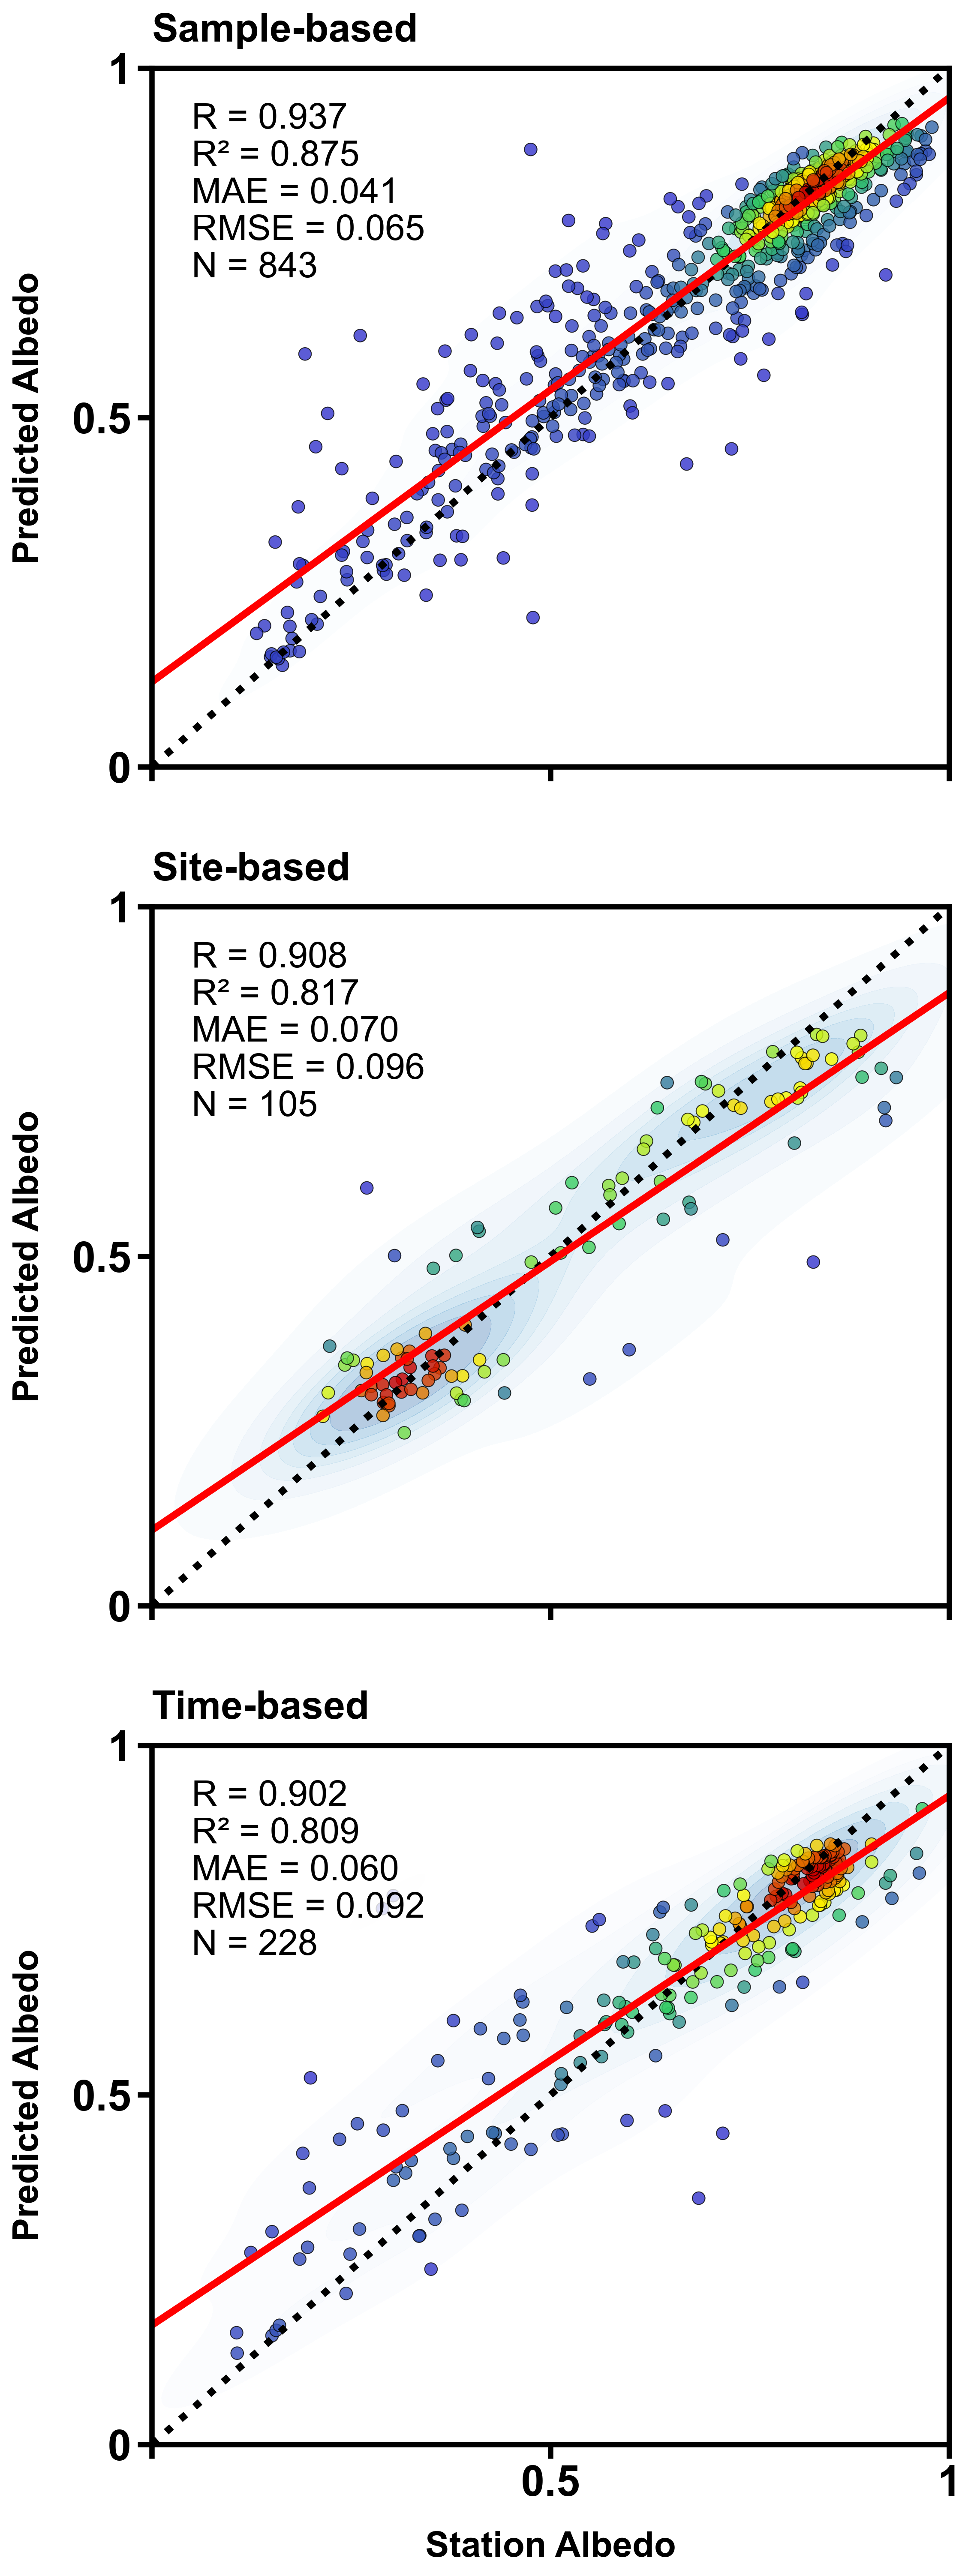

✅ 完成！
1. 标题已移除abc前缀。
2. 统计文字已恢复细体。
3. 底部X轴起点'0'已隐藏。
保存路径: C:\Users\greenlandProject\ERA5LAND\Merged_Vertical_Clean_Titles.png


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, gaussian_kde
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.base import clone
import xgboost as xgb
import lightgbm as lgb
import catboost
import os
from matplotlib.colors import LinearSegmentedColormap

# ==========================================
# 1. 全局配置 (npj 风格：竖排 + 粗体 + 大字)
# ==========================================
FILE_PATH_MAIN = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
FILE_PATH_TIME = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917.xlsx"

# 全局字体设置
FONT_SIZE = 24
FONT_FAMILY = 'Arial'

plt.rcParams.update({
    'font.family': FONT_FAMILY,
    'font.weight': 'bold',          # 全局大部分文字加粗
    'font.size': FONT_SIZE,
    
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'axes.linewidth': 3.0,          # 边框加粗
    
    'xtick.labelsize': FONT_SIZE,
    'ytick.labelsize': FONT_SIZE,
    'xtick.major.width': 3.0,
    'ytick.major.width': 3.0,
    'xtick.major.size': 8.0,
    'ytick.major.size': 8.0,
    
    'lines.linewidth': 4.0,
    'figure.dpi': 300
})

def calculate_metrics(y_true, y_pred):
    r, _ = pearsonr(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return r, r2, mae, rmse

def plot_performance(ax, y_true, y_pred, title_str, is_bottom=False):
    """
    is_bottom: 布尔值，控制是否显示X轴标签以及处理0刻度重叠问题
    """
    # 1. 计算指标
    r, r2, mae, rmse = calculate_metrics(y_true, y_pred)
    n = len(y_true)
    
    # 2. 绘制背景 KDE (浅蓝色)
    sns.kdeplot(
        x=y_true, y=y_pred, 
        fill=True, cmap="Blues", levels=8, alpha=0.3, thresh=0.05, ax=ax
    )
    
    # 3. 绘制前景散点 (自定义色带)
    xy = np.vstack([y_true, y_pred])
    z = gaussian_kde(xy)(xy)
    
    colors_list = [
        (0.0,  (0.2, 0.2, 0.8)),   # 蓝
        (0.3,  (0.2, 0.8, 0.4)),   # 绿
        (0.6,  (1.0, 1.0, 0.0)),   # 黄
        (1.0,  (0.8, 0.0, 0.0))    # 红
    ]
    cmap = LinearSegmentedColormap.from_list("custom_density_cmap", colors_list)
    
    ax.scatter(y_true, y_pred, c=z, cmap=cmap, s=50, alpha=0.8, edgecolors='black', linewidths=0.5)
    
    # 4. 绘制参考线
    ax.plot([0, 1], [0, 1], color='black', linestyle=':', label='1:1 Line')
    
    # 回归线
    a, b = np.polyfit(y_true, y_pred, 1)
    x_line = np.linspace(0, 1, 100)
    y_line = a * x_line + b
    ax.plot(x_line, y_line, color='red', linestyle='-', label='Fit Line')
    
    # 5. 设置刻度与标签
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    
    ticks = [0, 0.5, 1]
    
    # Y轴：正常显示
    ax.set_yticks(ticks)
    ax.set_yticklabels(['0', '0.5', '1'], fontweight='bold')
    ax.set_ylabel("Predicted Albedo", fontweight='bold', labelpad=15)
    
    # X轴处理
    ax.set_xticks(ticks)
    if is_bottom:
        # 【修改点】: 底部子图，第一个刻度设为空字符串，消除重复的"0"
        ax.set_xticklabels(['', '0.5', '1'], fontweight='bold')
        ax.set_xlabel("Station Albedo", fontweight='bold', labelpad=15)
    else:
        # 非底部子图，隐藏数字
        ax.set_xticklabels([])
        ax.set_xlabel("")

    # 标题 (左对齐)
    ax.set_title(title_str, loc='left', pad=15, fontweight='bold')
    
    # 6. 添加统计文本
    # 【修改点】: fontweight='normal' 取消加粗
    text_x_pos = 0.05
    text_y_start = 0.95
    
    stats_text = (
        f'R = {r:.3f}\n'
        f'R² = {r2:.3f}\n'
        f'MAE = {mae:.3f}\n'
        f'RMSE = {rmse:.3f}\n'
        f'N = {n:,}'
    )
    
    ax.text(text_x_pos, text_y_start, stats_text, 
            transform=ax.transAxes, ha='left', va='top', 
            fontsize=FONT_SIZE-4, fontweight='normal',  # 显式指定 normal
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=5))

# ==========================================
# 2. 数据处理与模型训练
# ==========================================

print(">>> 阶段 1: 读取与处理主数据...")
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

try:
    data = pd.read_csv(FILE_PATH_MAIN)
    data = data[~data["station"].isin(exclude_stations)]
    mask = ~data[target_column].isnull() & ~data[input_features].isnull().any(axis=1)
    data_clean = data[mask].copy()
    
    X = data_clean[input_features].astype(float)
    y = data_clean[target_column]
    stations = data_clean["station"]
except Exception as e:
    print(f"❌ 读取主CSV失败: {e}, 使用模拟数据")
    X = pd.DataFrame(np.random.rand(200, len(input_features)), columns=input_features)
    y = pd.Series(np.random.rand(200))
    stations = pd.Series(["TAS_L"]*100 + ["Other"]*100)
    data_clean = pd.concat([X, y, stations], axis=1)
    data_clean.rename(columns={0: 'station'}, inplace=True)

models = {
    'RF': RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'LGBM': lgb.LGBMRegressor(n_estimators=100, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': catboost.CatBoostRegressor(iterations=100, verbose=0, random_seed=42)
}

# --- Sample-based ---
print(">>> Training Sample-based...")
X_train, X_test, y_train, y_test, _, _ = train_test_split(X, y, stations, test_size=0.2, random_state=42)
preds_sample = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds_sample.append(model.predict(X_test))
y_pred_sample = np.mean(np.column_stack(preds_sample), axis=1)

# --- Site-based ---
print(">>> Training Site-based...")
target_station = "TAS_L"
train_mask = data_clean['station'] != target_station
test_mask = data_clean['station'] == target_station
X_train_site = X[train_mask]
y_train_site = y[train_mask]
X_test_site = X[test_mask]
y_test_site = y[test_mask]

preds_site = []
if len(X_test_site) > 0:
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_train_site, y_train_site)
        preds_site.append(model_clone.predict(X_test_site))
    y_pred_site = np.mean(np.column_stack(preds_site), axis=1)
else:
    y_pred_site = []

# --- Time-based (Read Excel) ---
print(">>> Reading Time-based Excel...")
try:
    df_time = pd.read_excel(FILE_PATH_TIME)
    df_time = df_time.replace([np.inf, -np.inf], np.nan).dropna(subset=["st_albedo", "albedo_pred"])
    y_true_time = df_time["st_albedo"].astype(float).values
    y_pred_time = df_time["albedo_pred"].astype(float).values
except Exception as e:
    print(f"❌ 读取Excel失败: {e}, 使用模拟数据")
    y_true_time = np.random.rand(100)
    y_pred_time = y_true_time + np.random.normal(0, 0.05, 100)

# ==========================================
# 3. 绘图 (竖排 3x1)
# ==========================================
print(">>> 生成最终图表...")

# 设置画布：宽8，高24 (拉长)
fig, axes = plt.subplots(3, 1, figsize=(8, 24))

# 调整子图间距
plt.subplots_adjust(hspace=0.2) 

# 1. Sample-based (Top) -> 【修改点】: 去掉(a)
plot_performance(axes[0], y_test, y_pred_sample, "Sample-based", is_bottom=False)

# 2. Site-based (Middle) -> 【修改点】: 去掉(b)
if len(y_test_site) > 0:
    plot_performance(axes[1], y_test_site, y_pred_site, "Site-based", is_bottom=False)

# 3. Time-based (Bottom) -> 【修改点】: 去掉(c)
if len(y_true_time) > 0:
    plot_performance(axes[2], y_true_time, y_pred_time, "Time-based", is_bottom=True)

# 保存
out_dir = os.path.dirname(FILE_PATH_MAIN)
if not out_dir: out_dir = "."
save_path = os.path.join(out_dir, "Merged_Vertical_Clean_Titles.png")

print(f"--- 正在保存图像 ---")
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"✅ 完成！\n1. 标题已移除abc前缀。\n2. 统计文字已恢复细体。\n3. 底部X轴起点'0'已隐藏。\n保存路径: {save_path}")

In [7]:


import os
import time
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ===================== PATHS =====================
CSV_PATH = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
OUT_DIR = os.path.dirname(CSV_PATH) or "."

# ===================== CONFIG =====================
RANDOM_STATE = 42
SAMPLE_OOF_FOLDS = 5
MONTH_FILTER = None  # e.g., [4,5,6,7,8,9] or None

# ===================== COLUMN DETECTION =====================
def pick_first_existing(cols, candidates, required=True):
    for c in candidates:
        if c in cols:
            return c
    if required:
        raise KeyError(f"Missing required column. Tried: {candidates}")
    return None

def infer_target_col(cols):
    candidates = [
        "st_albedo", "albedo", "outputalbedo", "obs_albedo", "target", "y",
        "ALBEDO", "Albedo"
    ]
    for c in candidates:
        if c in cols:
            return c
    albedo_like = [c for c in cols if "albedo" in c.lower()]
    if albedo_like:
        return albedo_like[0]
    raise KeyError("Cannot infer target (albedo) column. Please rename/add one.")

def safe_numeric_df(df, feature_cols):
    X = df[feature_cols].copy()
    for c in feature_cols:
        if not np.issubdtype(X[c].dtype, np.number):
            X[c] = pd.to_numeric(X[c], errors="coerce")
    return X

# ===================== MODELS (STACKING) =====================
from sklearn.base import clone
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

def make_base_models(random_state=42):
    # Reasonable defaults; keep runtime acceptable for LOYO/LOSO
    return {
        "RF": RandomForestRegressor(
            n_estimators=500, n_jobs=-1, random_state=random_state
        ),
        "GBR": GradientBoostingRegressor(random_state=random_state),
        "XGB": xgb.XGBRegressor(
            n_estimators=800, learning_rate=0.05, max_depth=6,
            subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0, random_state=random_state,
            n_jobs=-1, tree_method="hist"
        ),
        "LGBM": lgb.LGBMRegressor(
            n_estimators=1200, learning_rate=0.03, num_leaves=63,
            subsample=0.8, colsample_bytree=0.8,
            random_state=random_state, n_jobs=-1
        ),
        "CAT": CatBoostRegressor(
            iterations=1500, learning_rate=0.03, depth=8,
            loss_function="RMSE",
            random_seed=random_state,
            verbose=False
        ),
    }

def fit_predict_stacking(X_train, y_train, X_test, random_state=42):
    """
    For each split:
      - fit base models on train
      - get base preds on train and test
      - fit Ridge meta on base train preds
      - meta predicts base test preds
    No leakage into test: everything is trained only on train.
    """
    base = make_base_models(random_state=random_state)

    base_train_preds = []
    base_test_preds = []

    for _, m in base.items():
        model = clone(m)
        model.fit(X_train, y_train)
        base_train_preds.append(model.predict(X_train))
        base_test_preds.append(model.predict(X_test))

    Z_train = np.vstack(base_train_preds).T
    Z_test  = np.vstack(base_test_preds).T

    meta = Ridge(alpha=1.0, random_state=random_state)
    meta.fit(Z_train, y_train)
    return meta.predict(Z_test)

# ===================== CV PREDICTIONS =====================
def oof_kfold_predictions(X, y, n_splits=5, random_state=42):
    preds = np.full((len(y),), np.nan, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    for fold, (tr, te) in enumerate(kf.split(X), 1):
        Xtr, Xte = X.iloc[tr], X.iloc[te]
        ytr = y.iloc[tr]

        preds[te] = fit_predict_stacking(Xtr, ytr, Xte, random_state=random_state)

        rmse = np.sqrt(mean_squared_error(y.iloc[te], preds[te]))  # sklearn-old compatible
        print(f"[Sample OOF] fold {fold}/{n_splits}  test_n={len(te)}  RMSE={rmse:.4f}")

    return preds

def group_logo_predictions(X, y, groups, tag="LOSO", random_state=42):
    preds = np.full((len(y),), np.nan, dtype=float)
    logo = LeaveOneGroupOut()

    i = 0
    for tr, te in logo.split(X, y, groups=groups):
        g = pd.Series(groups).iloc[te].iloc[0]
        i += 1

        Xtr, Xte = X.iloc[tr], X.iloc[te]
        ytr = y.iloc[tr]

        preds[te] = fit_predict_stacking(Xtr, ytr, Xte, random_state=random_state)

        rmse = np.sqrt(mean_squared_error(y.iloc[te], preds[te]))  # sklearn-old compatible
        print(f"[{tag}] group {i}  ({g})  test_n={len(te)}  RMSE={rmse:.4f}")

    return preds

# ===================== STATION METRICS (YOUR LOGIC) =====================
from scipy.stats import pearsonr

def station_metrics_table(df_all, station_col, lon_col, lat_col, y_col, pred_col, out_csv):
    """
    Output columns match your plotting expectations:
      station, longitude, latitude, R, RMSE, Bias, Bias_abs
    where Bias_abs is MAE (mean absolute error).
    """
    sub = df_all[[station_col, lon_col, lat_col, y_col, pred_col]].copy()
    sub = sub.dropna(subset=[y_col, pred_col, lon_col, lat_col, station_col])

    rows = []
    for st, g in sub.groupby(station_col):
        y_true = g[y_col].to_numpy(dtype=float)
        y_pred = g[pred_col].to_numpy(dtype=float)

        n = len(y_true)
        err = y_pred - y_true

        # RMSE/MAE/Bias always defined if n>=1
        rmse = float(np.sqrt(np.mean(err**2)))
        mae  = float(np.mean(np.abs(err)))      # <-- MAE
        bias = float(np.mean(err))              # mean error

        # Pearson r needs variation and n>=3 to be meaningful
        r_val = np.nan
        if n >= 3 and np.nanstd(y_true) > 0 and np.nanstd(y_pred) > 0:
            r_val = float(pearsonr(y_true, y_pred)[0])

        rows.append({
            "station": st,
            "longitude": float(g[lon_col].iloc[0]),
            "latitude": float(g[lat_col].iloc[0]),
            "n_test": int(n),
            "R": r_val,
            "RMSE": rmse,
            "Bias": bias,
            "Bias_abs": mae,   # <-- this is MAE for your map
        })

    out = pd.DataFrame(rows)
    out = out.sort_values("station").reset_index(drop=True)
    out.to_csv(out_csv, index=False)
    print(f"[METRICS SAVED] {out_csv}  (stations={len(out)})")
    return out

# ===================== MAIN =====================
def main():
    if not os.path.exists(CSV_PATH):
        raise FileNotFoundError(CSV_PATH)

    df = pd.read_csv(CSV_PATH)
    print(f"[LOAD] {CSV_PATH}")
    print(f"[SHAPE] {df.shape}")

    cols = df.columns.tolist()

    col_station = pick_first_existing(cols, ["station", "Station", "site", "SITE"], required=True)
    col_lat     = pick_first_existing(cols, ["latitude", "lat", "Latitude", "LAT"], required=True)
    col_lon     = pick_first_existing(cols, ["longitude", "lon", "Longitude", "LON"], required=True)
    col_year    = pick_first_existing(cols, ["year", "Year", "YYYY"], required=True)
    col_month   = pick_first_existing(cols, ["month", "Month", "MM"], required=False)
    col_y       = infer_target_col(cols)

    print(f"[COL] station={col_station} lon={col_lon} lat={col_lat} year={col_year} month={col_month} target={col_y}")

    # Work copy (optionally filter months)
    df_work = df.copy()
    if MONTH_FILTER is not None:
        if col_month is None:
            raise KeyError("MONTH_FILTER set but no month column in CSV.")
        before = len(df_work)
        df_work = df_work[df_work[col_month].isin(MONTH_FILTER)].copy()
        print(f"[FILTER] month in {MONTH_FILTER}: {before} -> {len(df_work)}")

    # Build features: all columns except metadata and target
    drop_cols = {col_y, col_station, col_lat, col_lon, col_year}
    if col_month:
        drop_cols.add(col_month)

    candidate_feats = [c for c in df_work.columns if c not in drop_cols]
    X_all = safe_numeric_df(df_work, candidate_feats)
    y_all = pd.to_numeric(df_work[col_y], errors="coerce")

    # Keep rows with target
    ok = y_all.notna()
    df_work = df_work.loc[ok].copy()
    X_all   = X_all.loc[ok].copy()
    y_all   = y_all.loc[ok].copy()

    # Drop constant / all-NaN features
    nunique = X_all.nunique(dropna=True)
    good_feat_cols = nunique[nunique >= 2].index.tolist()
    X_all = X_all[good_feat_cols].copy()

    # Drop rows with any NaN in features (strict)
    ok2 = X_all.notna().all(axis=1)
    dropped = int((~ok2).sum())
    if dropped > 0:
        print(f"[CLEAN] drop rows with NaN in features: {dropped}")
    df_work = df_work.loc[ok2].copy()
    X_all   = X_all.loc[ok2].copy()
    y_all   = y_all.loc[ok2].copy()

    print(f"[MODEL DATA] n={len(df_work)}  p={X_all.shape[1]}")

    # ===== 1) Sample-wise OOF =====
    print("\n==== 1) Sample-wise OOF predictions (pred_sample) ====")
    pred_sample = oof_kfold_predictions(X_all, y_all, n_splits=SAMPLE_OOF_FOLDS, random_state=RANDOM_STATE)

    # ===== 2) Leave-one-year-out =====
    print("\n==== 2) Leave-one-year-out predictions (pred_year) ====")
    groups_year = df_work[col_year].astype(str).values
    pred_year = group_logo_predictions(X_all, y_all, groups_year, tag="LOYO", random_state=RANDOM_STATE)

    # ===== 3) Leave-one-station-out =====
    print("\n==== 3) Leave-one-station-out predictions (pred_loso) ====")
    groups_station = df_work[col_station].astype(str).values
    pred_loso = group_logo_predictions(X_all, y_all, groups_station, tag="LOSO", random_state=RANDOM_STATE)

    # Write predictions back to original df
    out = df.copy()
    for c in ["pred_sample", "pred_year", "pred_loso"]:
        if c not in out.columns:
            out[c] = np.nan

    out.loc[df_work.index, "pred_sample"] = pred_sample
    out.loc[df_work.index, "pred_year"]   = pred_year
    out.loc[df_work.index, "pred_loso"]   = pred_loso

    # Backup then overwrite merged_allfeature.csv
    ts = time.strftime("%Y%m%d_%H%M%S")
    backup = CSV_PATH.replace(".csv", f"_backup_{ts}.csv")
    out.to_csv(backup, index=False)
    print(f"\n[BACKUP SAVED] {backup}")

    out.to_csv(CSV_PATH, index=False)
    print(f"[OVERWRITE SAVED] {CSV_PATH}")

    print("\n[CHECK] non-null counts:")
    print("  pred_sample:", int(out["pred_sample"].notna().sum()))
    print("  pred_year  :", int(out["pred_year"].notna().sum()))
    print("  pred_loso  :", int(out["pred_loso"].notna().sum()))

    # ===== Station metrics CSVs (for your 3x3 maps) =====
    sample_csv = os.path.join(OUT_DIR, "siteaccuracy_sample.csv")
    year_csv   = os.path.join(OUT_DIR, "siteaccuracy_year.csv")
    loso_csv   = os.path.join(OUT_DIR, "siteaccuracy_loso.csv")

    print("\n==== Station metrics (your logic) ====")
    station_metrics_table(out, col_station, col_lon, col_lat, col_y, "pred_sample", sample_csv)
    station_metrics_table(out, col_station, col_lon, col_lat, col_y, "pred_year",   year_csv)
    station_metrics_table(out, col_station, col_lon, col_lat, col_y, "pred_loso",   loso_csv)

    print("\nDONE ✅")

if __name__ == "__main__":
    main()


[LOAD] C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv
[SHAPE] (4455, 17)
[COL] station=station lon=longitude lat=latitude year=year month=month target=albedo
[MODEL DATA] n=4455  p=11

==== 1) Sample-wise OOF predictions (pred_sample) ====
[Sample OOF] fold 1/5  test_n=891  RMSE=0.0819
[Sample OOF] fold 2/5  test_n=891  RMSE=0.0811
[Sample OOF] fold 3/5  test_n=891  RMSE=0.0859
[Sample OOF] fold 4/5  test_n=891  RMSE=0.0797
[Sample OOF] fold 5/5  test_n=891  RMSE=0.0791

==== 2) Leave-one-year-out predictions (pred_year) ====
[LOYO] group 1  (1990)  test_n=3  RMSE=0.1697
[LOYO] group 2  (1993)  test_n=4  RMSE=0.0999
[LOYO] group 3  (1994)  test_n=7  RMSE=0.0886
[LOYO] group 4  (1995)  test_n=24  RMSE=0.0648
[LOYO] group 5  (1996)  test_n=44  RMSE=0.0578
[LOYO] group 6  (1997)  test_n=69  RMSE=0.0547
[LOYO] group 7  (1998)  test_n=72  RMSE=0.0571
[LOYO] group 8  (1999)  test_n=79  RMSE=0.0783
[LOYO] group 9  (2000)  test_n=82  RMSE=0.0511
[LOYO] group 10  (2001)  test_n=81  RM

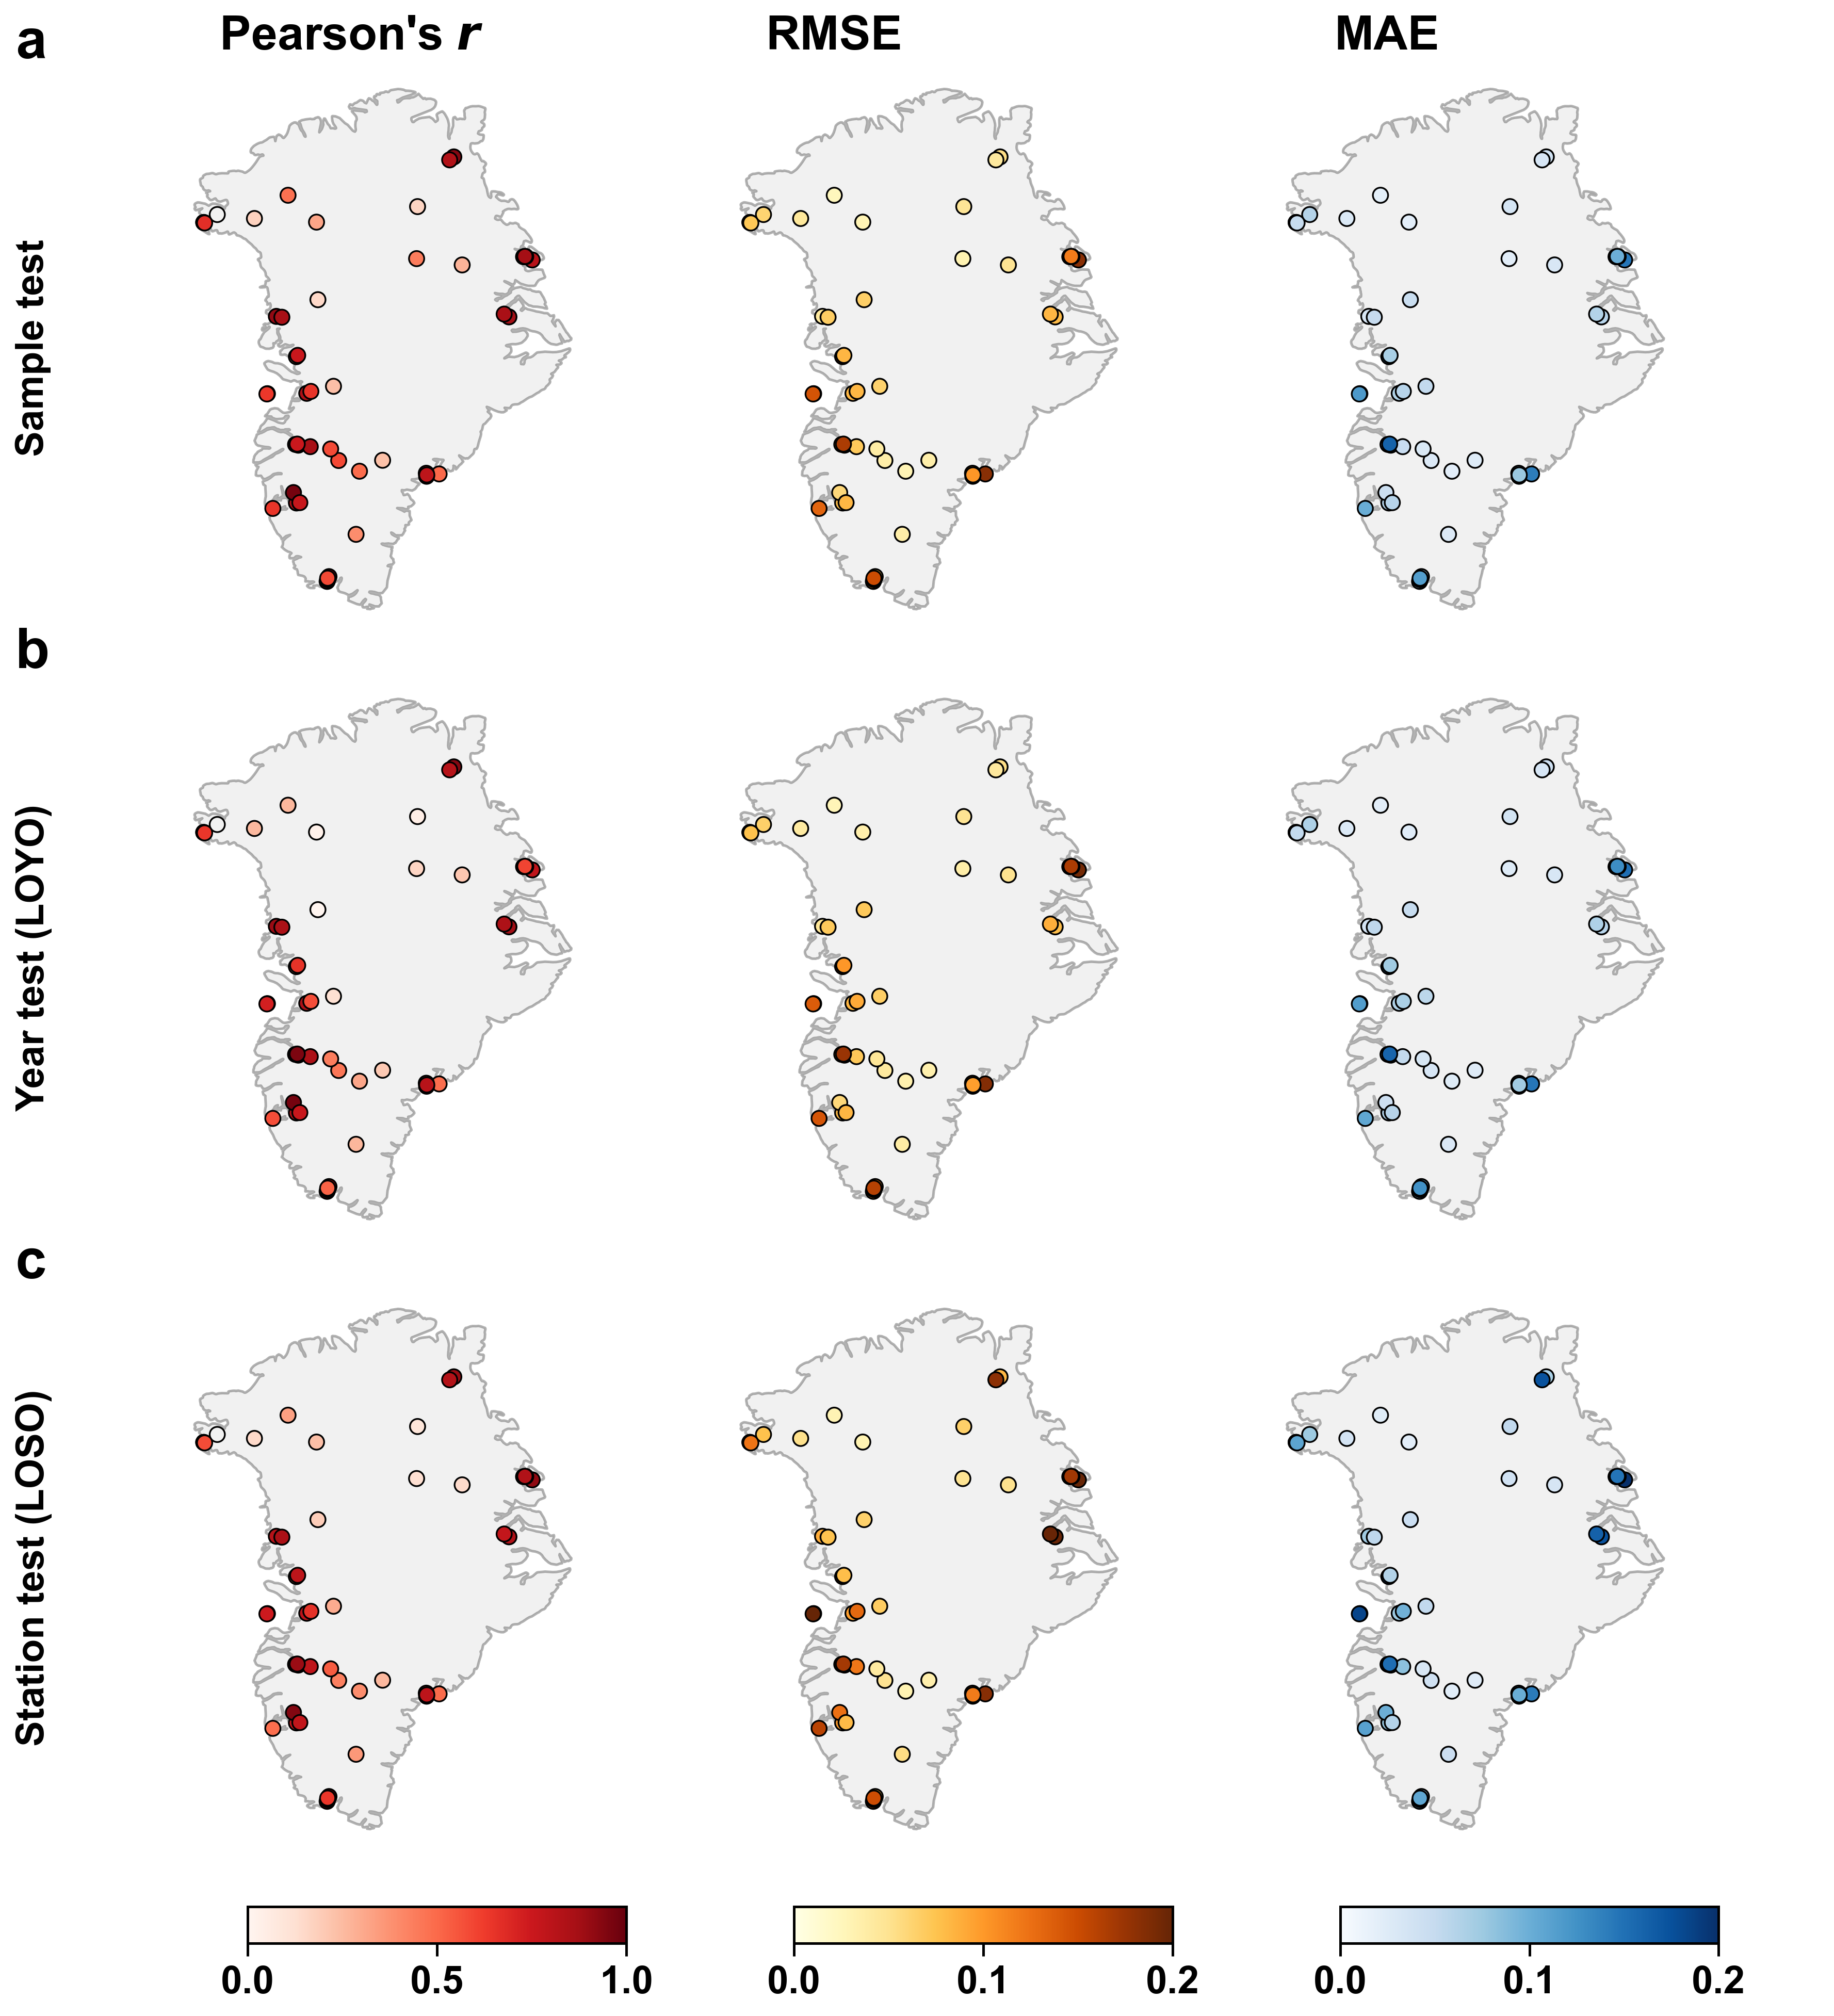

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib import rcParams

# ================== style ==================
rcParams["font.family"] = "Arial"
rcParams["font.size"] = 18

# ================== paths ==================
SAMPLE_CSV = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_sample.csv"
YEAR_CSV   = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_year.csv"
LOSO_CSV   = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_loso.csv"

# ================== read ==================
df_sample = pd.read_csv(SAMPLE_CSV)
df_year   = pd.read_csv(YEAR_CSV)
df_loso   = pd.read_csv(LOSO_CSV)

row_dfs = [df_sample, df_year, df_loso]

row_side_titles = ["Sample test", "Year test (LOYO)", "Station test (LOSO)"]
row_letters = ["a", "b", "c"]

# ================== plot config ==================
metrics = ["R", "RMSE", "Bias_abs"]                 # Bias_abs = MAE
col_titles = ["Pearson's $r$", "RMSE", "MAE"]

ticks_map = {
    "R": [0, 0.5, 1],
    "RMSE": [0, 0.1, 0.2],
    "Bias_abs": [0, 0.1, 0.2]
}
vmin_map = {"R": 0.0, "RMSE": 0.0, "Bias_abs": 0.0}
vmax_map = {"R": 1.0, "RMSE": 0.2, "Bias_abs": 0.2}

# colormaps: MAE -> white → blue (larger error = deeper blue)
cmaps = {
    "R": "Reds",
    "RMSE": "YlOrBr",
    "Bias_abs": "Blues"
}

proj = ccrs.NorthPolarStereo(central_longitude=-45)

# ================== Greenland outline ==================
land_feature = cfeature.NaturalEarthFeature("physical", "land", "50m")
all_geoms = list(land_feature.geometries())
greenland_geom = [
    g for g in all_geoms
    if g.bounds[0] > -75 and g.bounds[2] < -10
    and g.bounds[1] > 58 and g.bounds[3] > 70
]
greenland_main = sorted(greenland_geom, key=lambda x: x.area, reverse=True)[:1]

# ================== figure ==================
fig = plt.figure(figsize=(12.2, 14))

gs = fig.add_gridspec(
    3, 3,
    left=0.12, right=0.985,
    top=0.94, bottom=0.13,
    wspace=0.01, hspace=0.14
)

axes = np.empty((3, 3), dtype=object)
scatters = {}

for r_i, df in enumerate(row_dfs):
    for c_i, m in enumerate(metrics):
        ax = fig.add_subplot(gs[r_i, c_i], projection=proj)
        axes[r_i, c_i] = ax

        ax.set_extent([-56, -20, 59, 83.6], ccrs.PlateCarree())

        ax.patch.set_visible(False)
        try:
            ax.spines["geo"].set_visible(False)
        except Exception:
            pass

        ax.add_geometries(
            greenland_main,
            crs=ccrs.PlateCarree(),
            facecolor="lightgray",
            edgecolor="black",
            linewidth=1.2,
            alpha=0.3,
            zorder=1
        )

        sc = ax.scatter(
            df["longitude"], df["latitude"],
            c=df[m],
            cmap=cmaps[m],
            s=50,
            edgecolors="black",
            linewidth=0.8,
            transform=ccrs.PlateCarree(),
            zorder=5,
            vmin=vmin_map[m],
            vmax=vmax_map[m]
        )

        if r_i == 2:
            scatters[m] = sc

        ax.set_aspect("auto")

# ================== Left-side row letters + vertical row titles ==================
X_LEFT = 0.03
for r_i in range(3):
    pos = axes[r_i, 0].get_position()
    y_top = pos.y1
    y_mid = (pos.y0 + pos.y1) / 2

    fig.text(
        X_LEFT, y_top + 0.005, row_letters[r_i],
        ha="left", va="bottom",
        fontsize=26, fontweight="bold"
    )

    fig.text(
        X_LEFT, y_mid, row_side_titles[r_i],
        ha="left", va="center",
        rotation=90,
        fontsize=18, fontweight="bold"
    )

# ================== Column titles (MAE further right) ==================
BASE_SHIFT = 0.018
MAE_EXTRA_SHIFT = 0.012  # extra right shift ONLY for MAE

for c_i, title in enumerate(col_titles):
    pos = axes[0, c_i].get_position()
    shift = BASE_SHIFT + (MAE_EXTRA_SHIFT if title == "MAE" else 0.0)
    x = pos.x0 + shift
    y = pos.y1 + 0.01
    fig.text(x, y, title, ha="left", va="bottom", fontsize=22, fontweight="bold")

# ================== Column-shared horizontal colorbars ==================
CBAR_LEN = 0.70
CBAR_LEFT_SHIFT = 0.010

for c_i, m in enumerate(metrics):
    ax_last = axes[2, c_i]
    pos = ax_last.get_position()

    cb_width = pos.width * CBAR_LEN
    cb_height = 0.017
    cb_left = pos.x0 + (pos.width - cb_width) / 2 - CBAR_LEFT_SHIFT
    cb_bottom = pos.y0 - 0.050

    cax = fig.add_axes([cb_left, cb_bottom, cb_width, cb_height])
    cbar = fig.colorbar(scatters[m], cax=cax, orientation="horizontal")
    cbar.set_ticks(ticks_map[m])

    cbar.ax.tick_params(labelsize=18, length=6, width=1.2, pad=4)
    for t in cbar.ax.get_xticklabels():
        t.set_fontweight("bold")
    cbar.outline.set_linewidth(1.2)

plt.show()


>>> Loading main CSV...
>>> Sample-based split...
>>> Site-based LOSO for TAS_L...
>>> Loading Excel for time-based 2025...


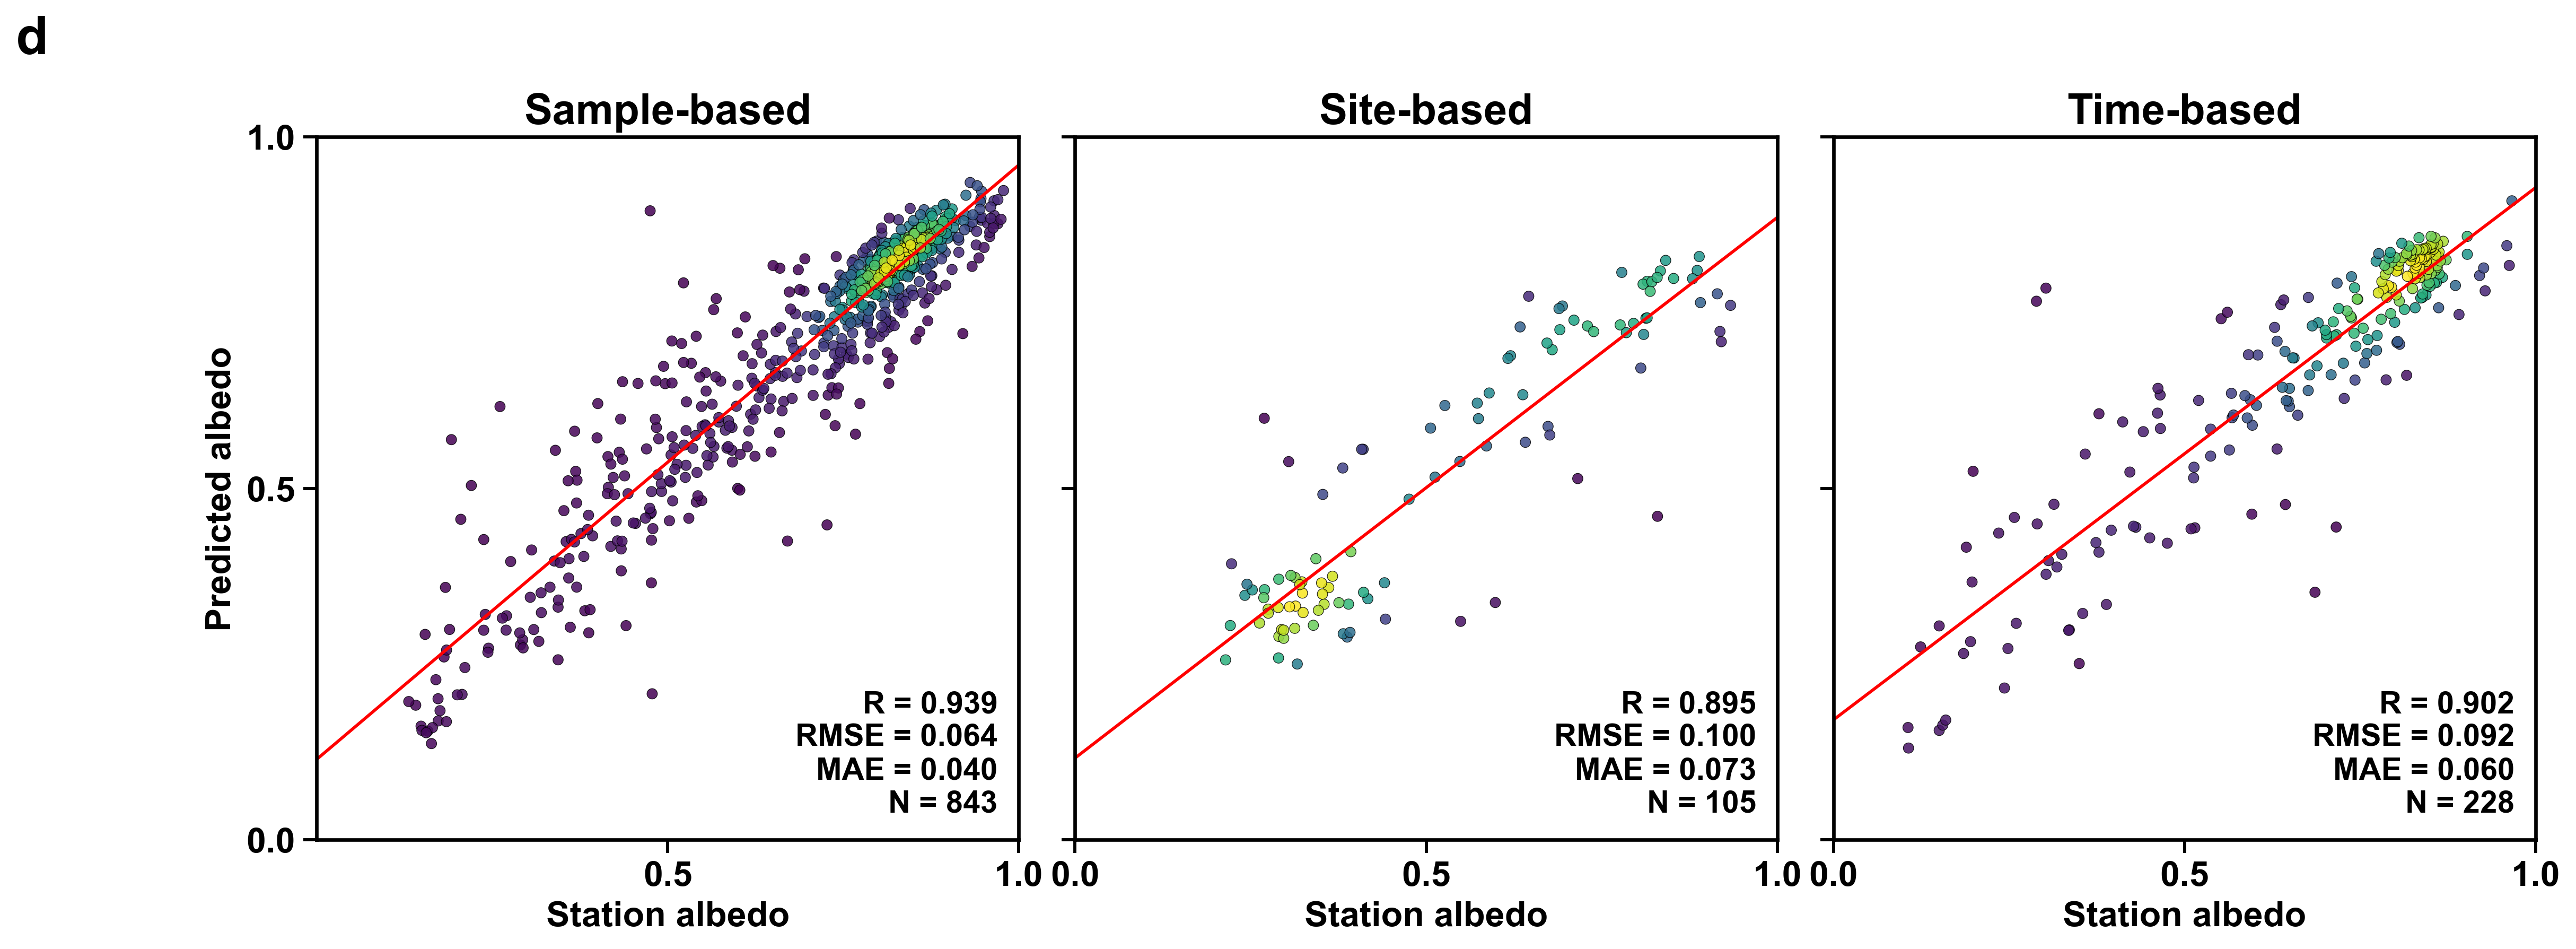

✅ Completed: Saved to
C:\Users\greenlandProject\ERA5LAND\Fig_Validation_DEF.png


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from scipy.stats import pearsonr, gaussian_kde
import xgboost as xgb
import lightgbm as lgb
import catboost

warnings.filterwarnings("ignore")

# ============================================================
# Configuration
# ============================================================
FILE_PATH_MAIN = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
FILE_PATH_TIME = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917.xlsx"
OUT_DIR = os.path.dirname(FILE_PATH_MAIN) or "."
OUT_FIG = os.path.join(OUT_DIR, "Fig_Validation_DEF.png")

TARGET = "albedo"
STATION_LOSO = "TAS_L"  # Site-based validation station
INPUT_FEATURES = ["longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
                  "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"]
EXCLUDE_STATIONS = ["QAS_M", "MIT", "NUK_K"]

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 16,
    "font.weight": "bold",  # 全局字体加粗
    "axes.linewidth": 1.6,
    "axes.labelweight": "bold",  # 坐标轴标签加粗
    "axes.titleweight": "bold",  # 标题加粗
    "xtick.major.width": 1.4,
    "ytick.major.width": 1.4,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "figure.dpi": 300
})

# ============================================================
# Utility Functions
# ============================================================
def metrics_r_rmse_mae(y_true, y_pred):
    """Calculate R, RMSE, MAE, N"""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    if len(y_true) < 3:
        return np.nan, np.nan, np.nan, len(y_true)
    r = pearsonr(y_true, y_pred)[0] if np.std(y_true) > 1e-12 and np.std(y_pred) > 1e-12 else np.nan
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(np.mean(np.abs(y_pred - y_true)))
    return float(r), rmse, mae, int(len(y_true))

def scatter_density(ax, x, y, title, show_ylabel, is_first_panel=False):
    """Create scatter plot with density coloring and statistics"""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    
    # Density calculation (subsample if too many points)
    x_kde, y_kde, use_sample = (x, y, False) if len(x) <= 6000 else (
        x[np.random.RandomState(42).choice(len(x), 6000, replace=False)],
        y[np.random.RandomState(42).choice(len(y), 6000, replace=False)], True)
    
    try:
        z = gaussian_kde(np.vstack([x_kde, y_kde]))(np.vstack([x_kde, y_kde]))
        if not use_sample:
            ax.scatter(x, y, c=z, s=22, edgecolors="black", linewidths=0.3, alpha=0.85)
        else:
            ax.scatter(x, y, s=16, color="0.4", alpha=0.35)
            ax.scatter(x_kde, y_kde, c=z, s=22, edgecolors="black", linewidths=0.3, alpha=0.85)
    except:
        ax.scatter(x, y, s=18, color="0.4", alpha=0.6)
    
    # ===============================1:1 line================================================
    #ax.plot([0, 1], [0, 1], linestyle=":", color="black", linewidth=1.2)
    
    # Linear fit line
    if len(x) >= 10:
        a, b = np.polyfit(x, y, 1)
        xx = np.linspace(0, 1, 100)
        ax.plot(xx, a * xx + b, color="red", linewidth=1.4)
    
    # Statistics box
    r, rmse, mae, n = metrics_r_rmse_mae(x, y)
    stats = f"R = {r:.3f}\nRMSE = {rmse:.3f}\nMAE = {mae:.3f}\nN = {n:,}"
    ax.text(0.97, 0.03, stats, transform=ax.transAxes, ha="right", va="bottom", 
            fontsize=14, fontweight="bold",
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=4))
    
    # Axes settings
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    
    # 对于第一个面板（d图），删除0.0刻度
    if is_first_panel:
        ax.set_xticks([0.5, 1.0])
    else:
        ax.set_xticks([0.0, 0.5, 1.0])
    
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_title(title, loc="center", pad=6, fontweight="bold")
    ax.set_box_aspect(1)
    ax.set_xlabel("Station albedo", fontweight="bold")
    ax.set_ylabel("Predicted albedo" if show_ylabel else "", fontweight="bold")
    if not show_ylabel:
        ax.set_yticklabels([])

# ============================================================
# Models
# ============================================================
models = {
    'RF': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_estimators=300, n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(n_estimators=300, random_state=42),
    'LGBM': lgb.LGBMRegressor(n_estimators=400, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': catboost.CatBoostRegressor(iterations=500, verbose=0, random_seed=42)
}

def fit_predict_ensemble(X_train, y_train, X_test):
    """Train ensemble of 5 models and return average predictions"""
    preds = [clone(m).fit(X_train, y_train).predict(X_test) for m in models.values()]
    return np.mean(np.column_stack(preds), axis=1)

# ============================================================
# Data Loading
# ============================================================
print(">>> Loading main CSV...")
data = pd.read_csv(FILE_PATH_MAIN)
data = data[~data["station"].isin(EXCLUDE_STATIONS)].copy()
mask = data[TARGET].notna() & ~data[INPUT_FEATURES].isna().any(axis=1)
data_clean = data.loc[mask].copy()

X = data_clean[INPUT_FEATURES].astype(float)
y = data_clean[TARGET].astype(float)
stations = data_clean["station"].astype(str)

# ============================================================
# Sample-based validation
# ============================================================
print(">>> Sample-based split...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_pred_sample = fit_predict_ensemble(X_train, y_train, X_test)

# ============================================================
# Site-based validation (LOSO for TAS_L)
# ============================================================
print(f">>> Site-based LOSO for {STATION_LOSO}...")
train_mask = stations != STATION_LOSO
test_mask = stations == STATION_LOSO
if test_mask.sum() == 0:
    raise RuntimeError(f"No samples found for station {STATION_LOSO}")
y_pred_site = fit_predict_ensemble(X[train_mask], y[train_mask], X[test_mask])
y_true_site = y[test_mask].values

# ============================================================
# Time-based validation (Blind-year 2025)
# ============================================================
print(">>> Loading Excel for time-based 2025...")
df_time = pd.read_excel(FILE_PATH_TIME)
df_2025 = df_time[df_time["year"] == 2025].copy()
df_2025 = df_2025.replace([np.inf, -np.inf], np.nan).dropna(subset=["st_albedo", "albedo_pred"])
y_true_time = df_2025["st_albedo"].astype(float).values
y_pred_time = df_2025["albedo_pred"].astype(float).values

# ============================================================
# Plotting: 1 row, 3 columns
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 缩小间距，使子图接近紧贴
plt.subplots_adjust(wspace=0.08)

# 绘制三个子图
scatter_density(axes[0], y_test.values, y_pred_sample, "Sample-based", show_ylabel=True, is_first_panel=True)
scatter_density(axes[1], y_true_site, y_pred_site, "Site-based", show_ylabel=False)
scatter_density(axes[2], y_true_time, y_pred_time, "Time-based", show_ylabel=False)

# 在整个图（figure）左上角添加小标题 d
# 使用 fig.text 并通过 transFigure 坐标定位，(0.02, 0.95) 对应画布左上角
fig.text(0.02, 0.95, "d", fontsize=24, fontweight="bold", fontfamily="Arial")

fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"✅ Completed: Saved to\n{OUT_FIG}")

>>> Loading Map CSVs...
>>> Loading main CSV for ML...
>>> Training Sample-based model...
>>> Training Site-based LOSO for TAS_L...
>>> Loading Excel for time-based 2025...
>>> Rendering Figure...
✅ Completed: Saved figure to C:\Users\11823\era5land


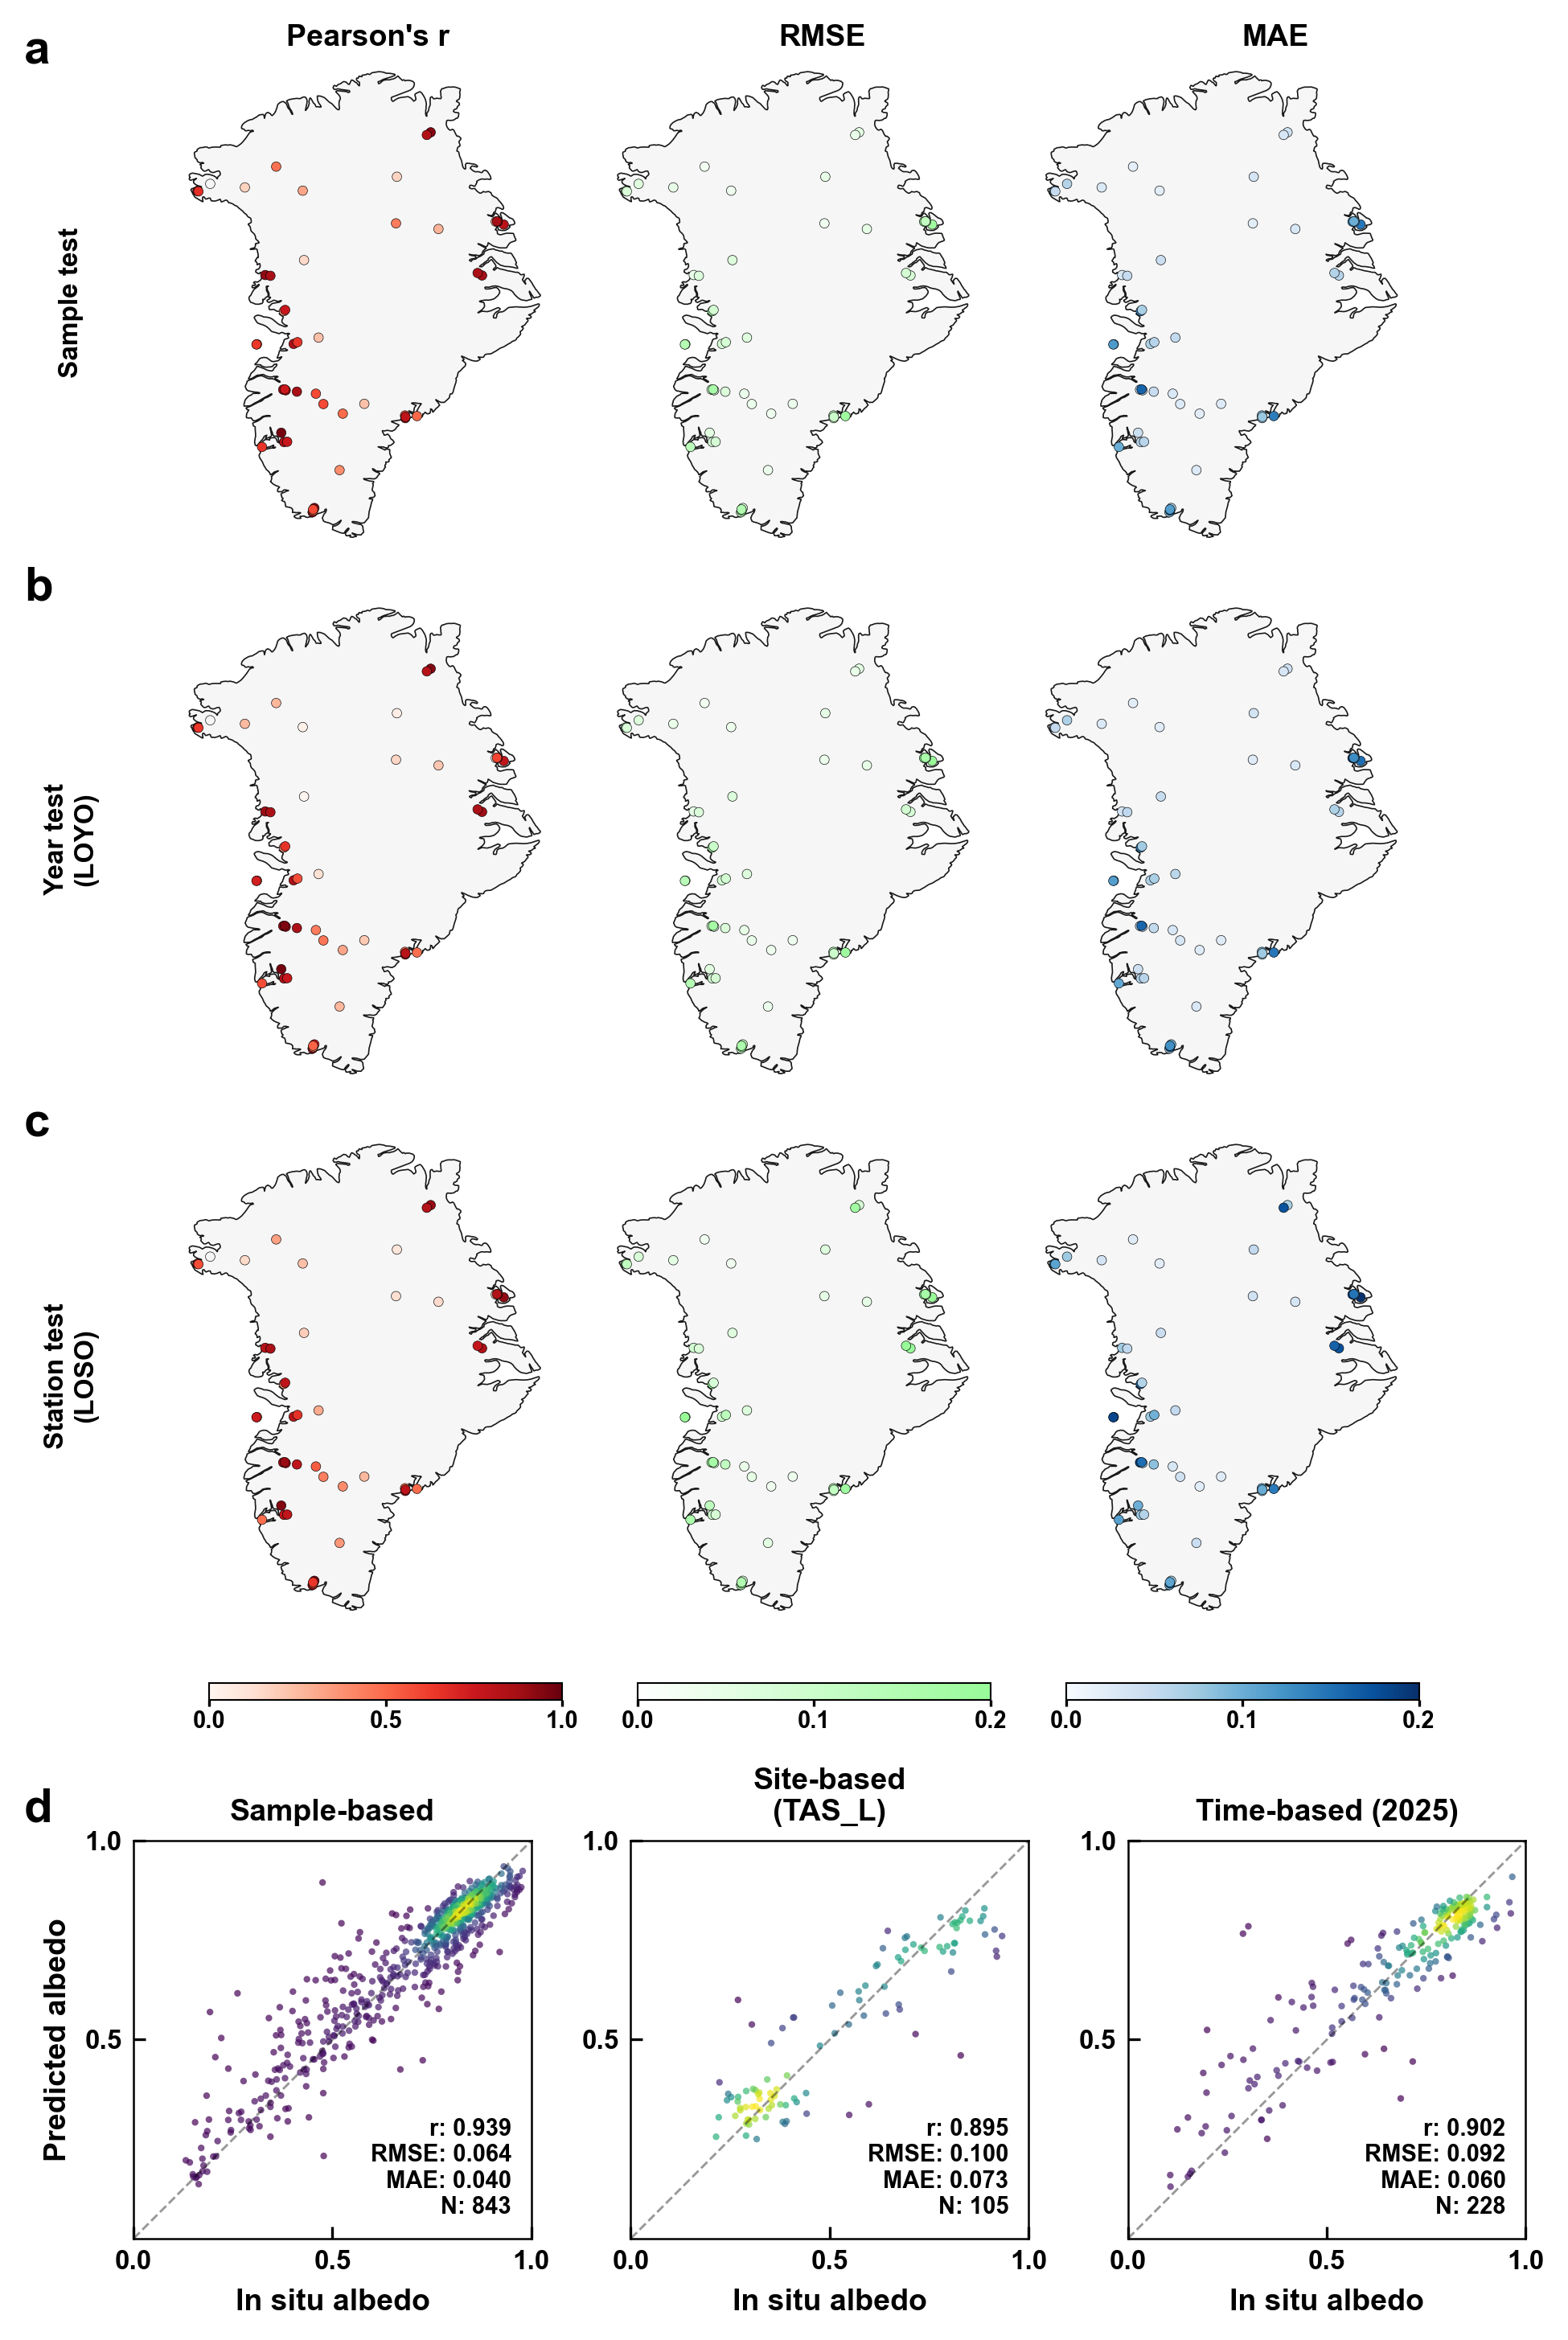

In [11]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import rcParams
from matplotlib.colors import LinearSegmentedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from scipy.stats import pearsonr, gaussian_kde
import xgboost as xgb
import lightgbm as lgb
import catboost

warnings.filterwarnings("ignore")

# ============================================================
# 1. NPJ Style & Fonts
# ============================================================
PT_PANEL_LABEL = 14
PT_COL_TITLE   = 9
PT_AXIS_LABEL  = 9
PT_TICK        = 8
PT_STATS       = 7
PT_CBAR_TICK   = 8
PT_ROW_TITLE   = 8

rcParams.update({
    "font.family"       : "Arial",
    "axes.linewidth"    : 0.6,
    "axes.labelweight"  : "bold",
    "figure.dpi"        : 300,
})

def metrics_r_rmse_mae(y_true, y_pred):
    yt, yp = np.asarray(y_true, float), np.asarray(y_pred, float)
    mask = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[mask], yp[mask]
    r = pearsonr(yt, yp)[0] if len(yt) > 2 else 0
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mae = np.mean(np.abs(yp - yt))
    return r, rmse, mae, len(yt)

# 自定义淡色方案
white_green_cmap = LinearSegmentedColormap.from_list("pale_green", ["#FFFFFF", "#98FB98"])
cmaps = {"R": "Reds", "RMSE": white_green_cmap, "MAE": "Blues"}

# ============================================================
# 2. Paths & ML Configuration
# ============================================================
# Map CSVs
SAMPLE_CSV = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_sample.csv"
YEAR_CSV   = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_year.csv"
LOSO_CSV   = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_loso.csv"

# ML Data
FILE_PATH_MAIN = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
FILE_PATH_TIME = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917.xlsx"

# 指定绝对输出路径和文件名前缀
OUT_DIR = r"C:\Users\11823\era5land"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_FIG_BASE = os.path.join(OUT_DIR, "Fig7")

TARGET = "albedo"
STATION_LOSO = "TAS_L"
INPUT_FEATURES = ["longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
                  "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"]
EXCLUDE_STATIONS = ["QAS_M", "MIT", "NUK_K"]

models = {
    'RF': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_estimators=300, n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(n_estimators=300, random_state=42),
    'LGBM': lgb.LGBMRegressor(n_estimators=400, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': catboost.CatBoostRegressor(iterations=500, verbose=0, random_seed=42)
}

def fit_predict_ensemble(X_train, y_train, X_test):
    preds = [clone(m).fit(X_train, y_train).predict(X_test) for m in models.values()]
    return np.mean(np.column_stack(preds), axis=1)

# ============================================================
# 3. Data Processing & Machine Learning Pipeline
# ============================================================
print(">>> Loading Map CSVs...")
row_dfs = []
for path in [SAMPLE_CSV, YEAR_CSV, LOSO_CSV]:
    df = pd.read_csv(path)
    if "Bias_abs" in df.columns:
        df = df.rename(columns={"Bias_abs": "MAE"})
    row_dfs.append(df)

print(">>> Loading main CSV for ML...")
data = pd.read_csv(FILE_PATH_MAIN)
data = data[~data["station"].isin(EXCLUDE_STATIONS)].copy()
mask = data[TARGET].notna() & ~data[INPUT_FEATURES].isna().any(axis=1)
data_clean = data.loc[mask].copy()

X = data_clean[INPUT_FEATURES].astype(float)
y = data_clean[TARGET].astype(float)
stations = data_clean["station"].astype(str)

print(">>> Training Sample-based model...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_te = y_test.values
y_pred_sample = fit_predict_ensemble(X_train, y_train, X_test)

print(f">>> Training Site-based LOSO for {STATION_LOSO}...")
train_mask = stations != STATION_LOSO
test_mask = stations == STATION_LOSO
y_pred_site = fit_predict_ensemble(X[train_mask], y[train_mask], X[test_mask])
y_true_site = y[test_mask].values

print(">>> Loading Excel for time-based 2025...")
df_time = pd.read_excel(FILE_PATH_TIME)
df_2025 = df_time[df_time["year"] == 2025].copy()
df_2025 = df_2025.replace([np.inf, -np.inf], np.nan).dropna(subset=["st_albedo", "albedo_pred"])
y_true_time = df_2025["st_albedo"].astype(float).values
y_pred_time = df_2025["albedo_pred"].astype(float).values

# ============================================================
# 4. Figure Setup & GridSpec
# ============================================================
print(">>> Rendering Figure...")
# 原始宽度 183mm 缩小 10% (乘以 0.9)
FIG_WIDTH_IN = (183 / 25.4) * 0.9
FIG_HEIGHT_IN = FIG_WIDTH_IN * 1.55
fig = plt.figure(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN))

# ── d 图 scatter grid ──────────────────────────────
# 两边空白缩窄：left 从 0.11 减小到 0.08，right 从 0.92 扩大到 0.97
# 稍微增加 wspace (从 0.22 到 0.25) 防止缩小后 X 轴标签重叠
gs_sc  = fig.add_gridspec(1, 3, left=0.08, right=0.97, bottom=0.06, top=0.23, wspace=0.25)

# ── abc 地图 grid ──────────────────────────────
# 配合底图向两侧扩张：left=0.11, right=0.98
MAP_LEFT  = 0.11
MAP_RIGHT = 0.98
gs_map = fig.add_gridspec(3, 3, left=MAP_LEFT, right=MAP_RIGHT,
                           top=0.96, bottom=0.32, wspace=-0.15, hspace=0.12)

proj = ccrs.NorthPolarStereo(central_longitude=-45)
land_feature = cfeature.NaturalEarthFeature("physical", "land", "50m")
greenland_main = sorted([g for g in list(land_feature.geometries()) if g.bounds[0]>-75 and g.bounds[1]>58], key=lambda x: x.area, reverse=True)[:1]

# ============================================================
# 4.1 A/B/C: Map Panels
# ============================================================
axes = np.empty((3, 3), dtype=object)
scatters = {}

row_letters = ['a', 'b', 'c']
row_side_titles = ['Sample test', 'Year test\n(LOYO)', 'Station test\n(LOSO)']
col_titles = ["Pearson's r", "RMSE", "MAE"]
metrics_list = ["R", "RMSE", "MAE"]

for r_i, df in enumerate(row_dfs):
    for c_i, m in enumerate(metrics_list):
        ax = fig.add_subplot(gs_map[r_i, c_i], projection=proj)
        axes[r_i, c_i] = ax
        ax.set_extent([-56, -20, 59, 83.6], ccrs.PlateCarree())
        
        ax.add_geometries(greenland_main, crs=ccrs.PlateCarree(), facecolor="#F5F5F5", edgecolor="black", linewidth=0.4, alpha=0.9, zorder=1)
        
        sc = ax.scatter(df["longitude"], df["latitude"], c=df[m], cmap=cmaps[m], s=8,
                        edgecolors="black", linewidth=0.15, transform=ccrs.PlateCarree(), zorder=5,
                        vmin=0, vmax=(0.2 if m != "R" else 1.0))
        if r_i == 2: scatters[m] = sc
        ax.set_aspect("auto")
        ax.axis("off")

# ── 行面板字母 & 行侧标题 ──
X_LEFT  = 0.01   # 面板字母 a/b/c 保持最左侧
X_TITLE = 0.04   # 因地图边界左移至 0.11，侧标题从 0.055 跟随左移至 0.04
for r_i in range(3):
    p = axes[r_i, 0].get_position()
    fig.text(X_LEFT, p.y1, row_letters[r_i], fontsize=PT_PANEL_LABEL, fontweight="bold")
    fig.text(X_TITLE, (p.y0+p.y1)/2, row_side_titles[r_i],
             ha="center", va="center", rotation=90, fontsize=PT_ROW_TITLE, fontweight="bold")

# ── 列标题 ──
# 重新计算新网格下的列中心：总宽 = 0.98 - 0.11 = 0.87，每列宽 0.29
# 新中心点：0.255, 0.545, 0.835。保留你原有的 -0.025 微调
ORIG_COL_CENTERS = [0.255 - 0.025, 0.545 - 0.025, 0.835 - 0.025]
for c_i, title in enumerate(col_titles):
    p = axes[0, c_i].get_position()
    fig.text(ORIG_COL_CENTERS[c_i], p.y1 + 0.005, title,
             ha="center", va="bottom", fontsize=PT_COL_TITLE, fontweight="bold")

# ── 色标 ──
for c_i, m in enumerate(metrics_list):
    p = axes[2, c_i].get_position()   
    cw, ch = p.width * 0.7, 0.007
    cax = fig.add_axes([p.x0 + (p.width - cw) / 2 - 0.03, 0.285, cw, ch])
    cb = fig.colorbar(scatters[m], cax=cax, orientation="horizontal")
    cb.set_ticks([0, 0.5, 1] if m == "R" else [0, 0.1, 0.2])
    cb.ax.tick_params(labelsize=PT_CBAR_TICK - 1, pad=1, length=2)
    for l in cb.ax.get_xticklabels(): l.set_fontweight('bold')
    cb.outline.set_linewidth(0.5)

# ============================================================
# 4.2 D: Scatter Validation Panels
# ============================================================
scatter_configs = [
    (y_te, y_pred_sample, "Sample-based"),
    (y_true_site, y_pred_site, f"Site-based\n({STATION_LOSO})"),
    (y_true_time, y_pred_time, "Time-based (2025)")
]

for i, (yt, yp, title) in enumerate(scatter_configs):
    ax = fig.add_subplot(gs_sc[0, i])
    ax.set_box_aspect(1) # 这里确保了子图的绝对正方形比例不变
    
    msk = np.isfinite(yt) & np.isfinite(yp)
    yt_c, yp_c = np.array(yt)[msk], np.array(yp)[msk]
    
    if len(yt_c) > 3000:
        idx = np.random.choice(len(yt_c), 3000, replace=False)
        yt_sub, yp_sub = yt_c[idx], yp_c[idx]
    else:
        yt_sub, yp_sub = yt_c, yp_c

    xy = np.vstack([yt_sub, yp_sub])
    z = gaussian_kde(xy)(xy)
    ax.scatter(yt_sub, yp_sub, c=z, s=4, cmap="viridis", alpha=0.7, edgecolor="none")
    ax.plot([0, 1], [0, 1], "k--", lw=0.7, alpha=0.4)
    
    r_val, rmse_val, mae_val, n_val = metrics_r_rmse_mae(yt_c, yp_c)
    stats_txt = f"r: {r_val:.3f}\nRMSE: {rmse_val:.3f}\nMAE: {mae_val:.3f}\nN: {n_val:,}"
    ax.text(0.95, 0.05, stats_txt, transform=ax.transAxes, ha="right", va="bottom", 
            fontsize=PT_STATS, fontweight="bold")
    
    ax.set_xticks([0.0, 0.5, 1.0])
    ax.set_yticks([0.5, 1.0]) 
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    
    ax.set_title(title, fontsize=PT_COL_TITLE, fontweight="bold", pad=6)
    # 顺手帮你把之前注释里的 Situ 拼写错误改成了 In situ
    ax.set_xlabel("In situ albedo", fontweight="bold", fontsize=PT_AXIS_LABEL)   
    if i == 0: ax.set_ylabel("Predicted albedo", fontweight="bold", fontsize=PT_AXIS_LABEL)
    ax.tick_params(direction="in", labelsize=PT_TICK)
    for l in (ax.get_xticklabels() + ax.get_yticklabels()): l.set_fontweight('bold')

fig.text(X_LEFT, 0.235, "d", fontsize=PT_PANEL_LABEL, fontweight="bold")

# ============================================================
# 5. Final Export
# ============================================================
for ext in ['png', 'pdf']:
    save_path = f"{OUT_FIG_BASE}.{ext}"
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"✅ Completed: Saved figure to {OUT_DIR}")

plt.show()

>>> Loading Map CSVs...
>>> Loading main CSV for ML...
>>> Training Sample-based model...
>>> Training Site-based LOSO for TAS_L...
>>> Loading Excel for time-based 2025...
>>> Rendering Figure...
>>> Loading Basin Shapefiles...
✅ Completed: Rendering finished (Not saved to disk).


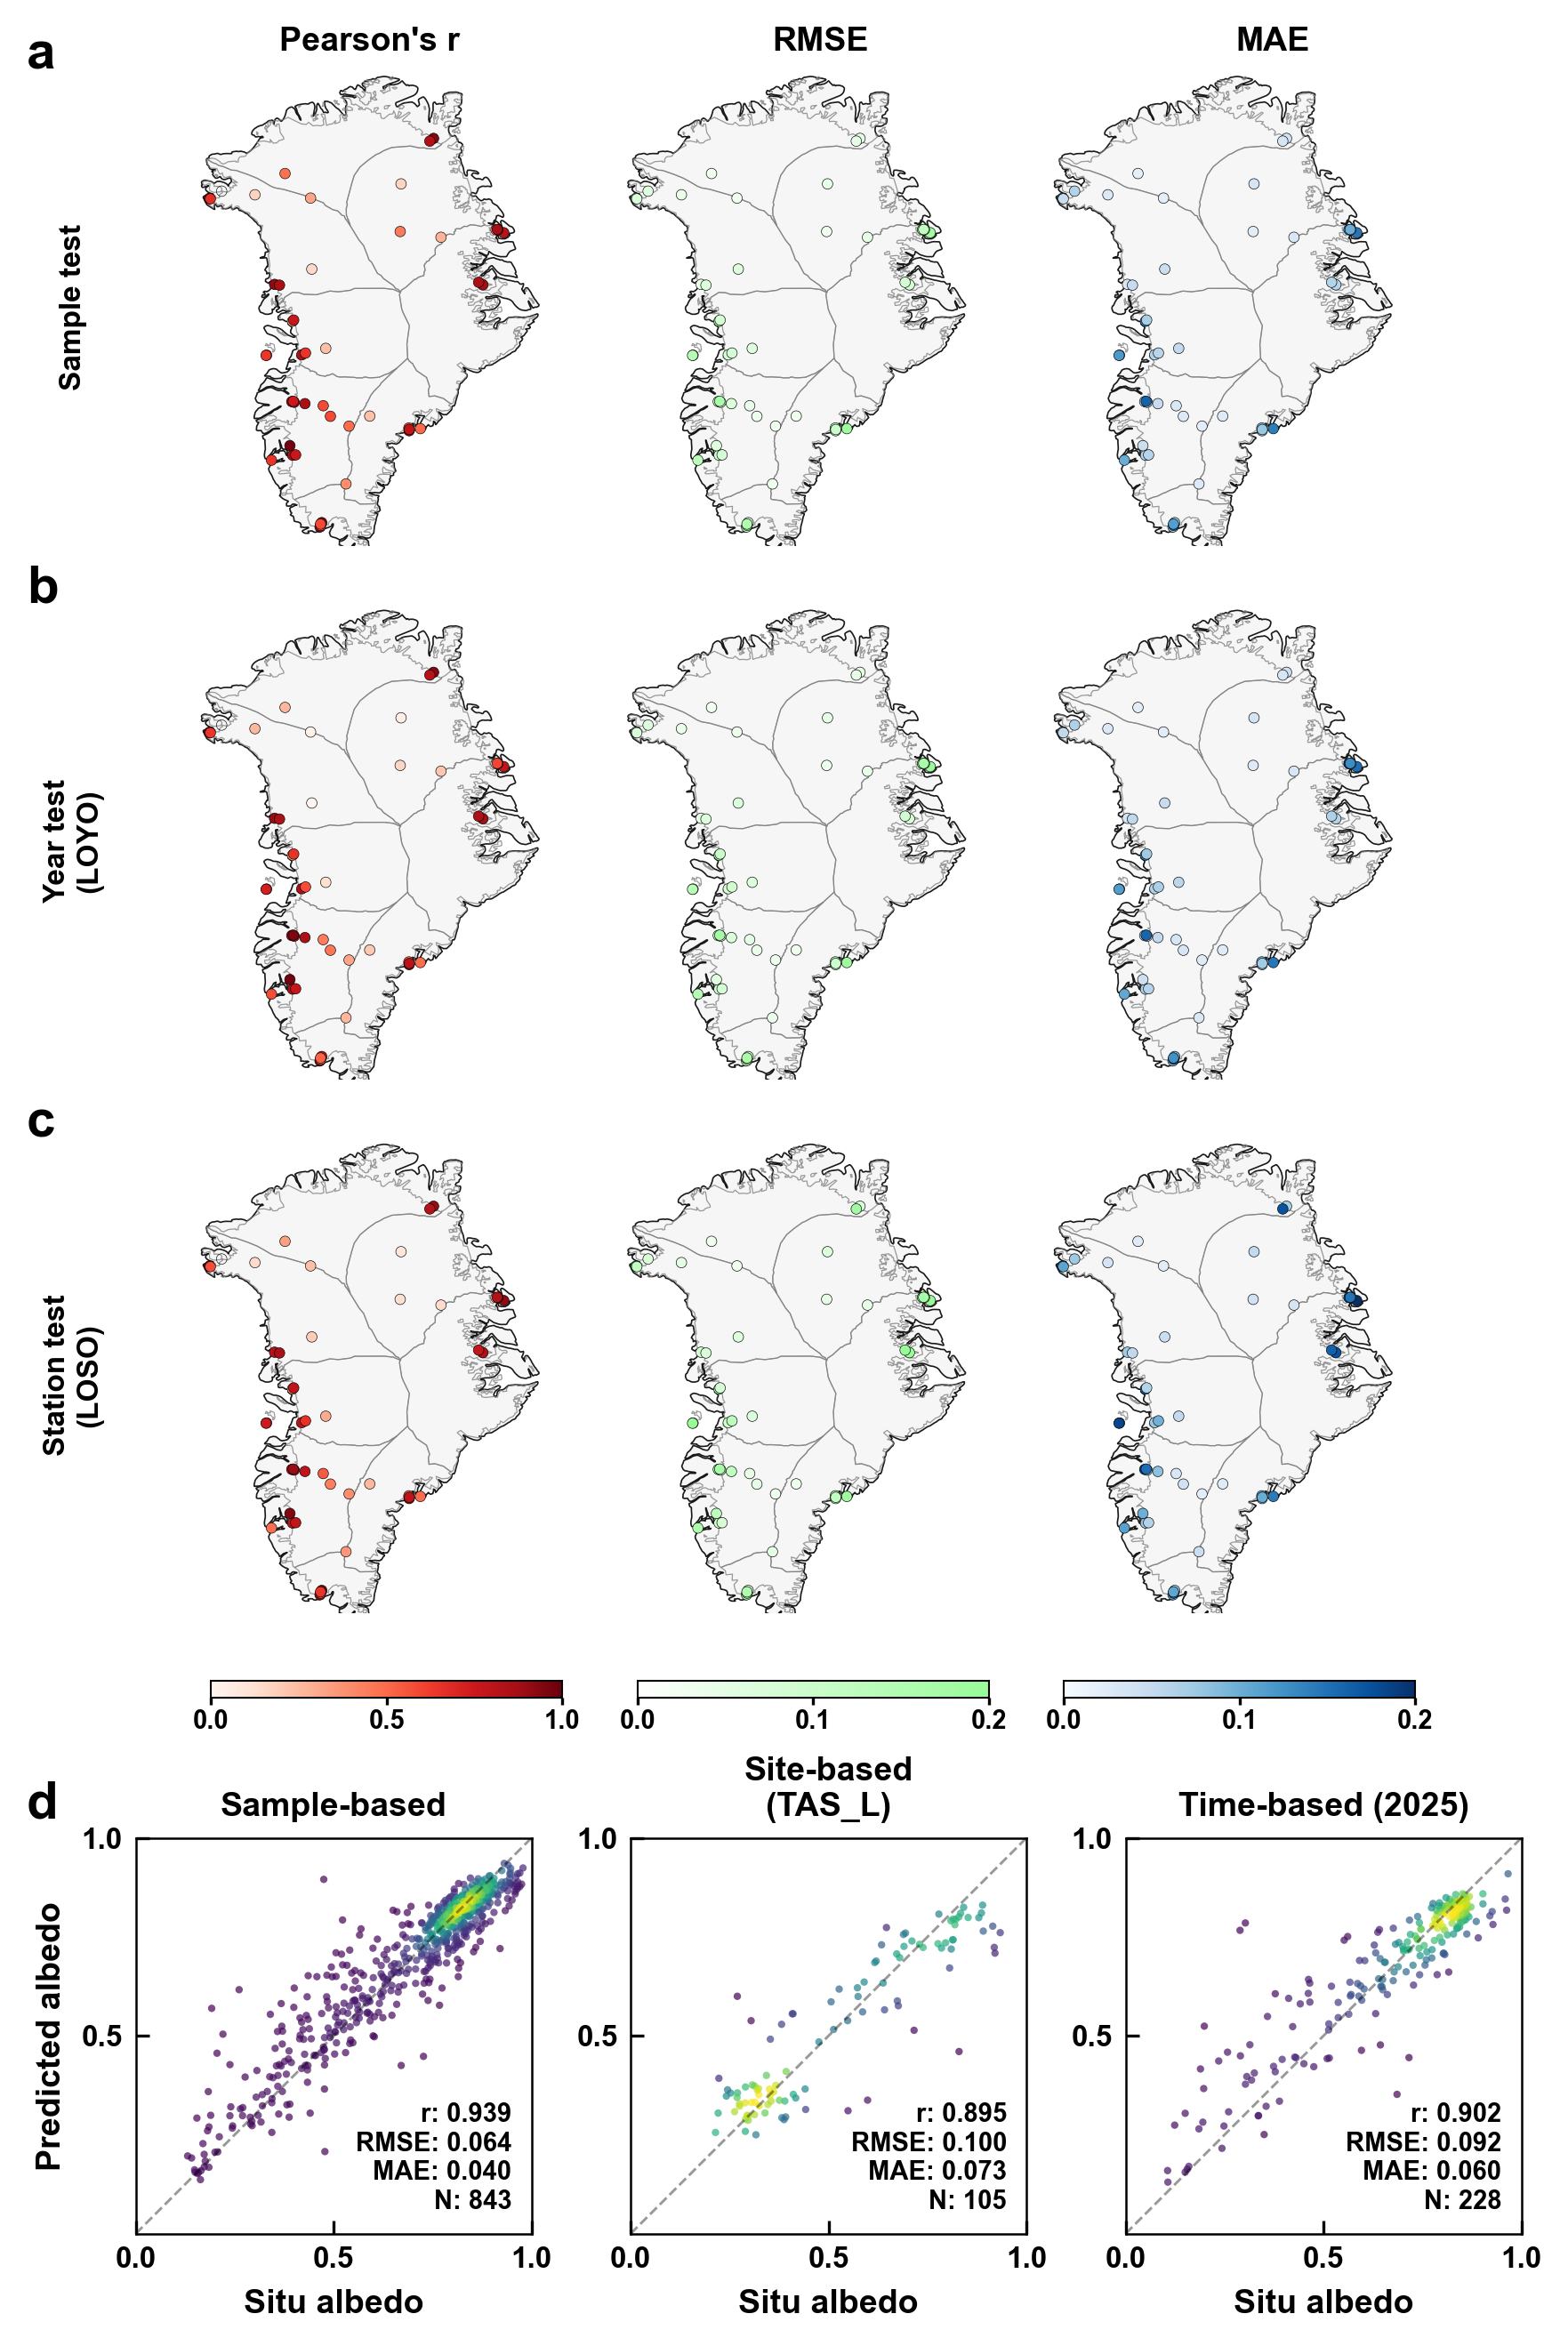

In [12]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import rcParams
from matplotlib.colors import LinearSegmentedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from scipy.stats import pearsonr, gaussian_kde
import xgboost as xgb
import lightgbm as lgb
import catboost

warnings.filterwarnings("ignore")

# ============================================================
# 1. NPJ Style & Fonts
# ============================================================
PT_PANEL_LABEL = 14
PT_COL_TITLE   = 9
PT_AXIS_LABEL  = 9
PT_TICK        = 8
PT_STATS       = 7
PT_CBAR_TICK   = 8
PT_ROW_TITLE   = 8

rcParams.update({
    "font.family"       : "Arial",
    "axes.linewidth"    : 0.6,
    "axes.labelweight"  : "bold",
    "figure.dpi"        : 300,
})

def metrics_r_rmse_mae(y_true, y_pred):
    yt, yp = np.asarray(y_true, float), np.asarray(y_pred, float)
    mask = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[mask], yp[mask]
    r = pearsonr(yt, yp)[0] if len(yt) > 2 else 0
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mae = np.mean(np.abs(yp - yt))
    return r, rmse, mae, len(yt)

# 自定义淡色方案
white_green_cmap = LinearSegmentedColormap.from_list("pale_green", ["#FFFFFF", "#98FB98"])
cmaps = {"R": "Reds", "RMSE": white_green_cmap, "MAE": "Blues"}

# ============================================================
# 2. Paths, Maps & ML Configuration
# ============================================================
# Map CSVs
SAMPLE_CSV = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_sample.csv"
YEAR_CSV   = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_year.csv"
LOSO_CSV   = r"C:\Users\greenlandProject\ERA5LAND\siteaccuracy_loso.csv"

# ML Data
FILE_PATH_MAIN = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
FILE_PATH_TIME = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917.xlsx"

# Shapefiles
BASIN_DIR    = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

# 流域名称映射 (备用)
BASIN_NAME_MAP = {
    "northwest": "NW", "southwest": "SW", "northeast": "NE", "southeast": "SE",
    "westnorth": "NW", "westsouth": "SW", "eastnorth": "NE", "eastsouth": "SE",
    "northwes":  "NW", "southwes":  "SW", "northeas":  "NE", "southeas":  "SE",
    "west": "W", "east": "E", "north": "N", "south": "S", "middle": "M",
    "nw": "NW", "sw": "SW", "ne": "NE", "se": "SE",
    "w": "W",   "e": "E",   "n": "N",   "s": "S",   "m": "M"
}
VALID_ABBR = {"NW", "NE", "SW", "SE", "W", "E", "N", "S"}

TARGET = "albedo"
STATION_LOSO = "TAS_L"
INPUT_FEATURES = ["longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
                  "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"]
EXCLUDE_STATIONS = ["QAS_M", "MIT", "NUK_K"]

models = {
    'RF': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_estimators=300, n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(n_estimators=300, random_state=42),
    'LGBM': lgb.LGBMRegressor(n_estimators=400, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': catboost.CatBoostRegressor(iterations=500, verbose=0, random_seed=42)
}

def fit_predict_ensemble(X_train, y_train, X_test):
    preds = [clone(m).fit(X_train, y_train).predict(X_test) for m in models.values()]
    return np.mean(np.column_stack(preds), axis=1)

# ============================================================
# 3. Data Processing & Machine Learning Pipeline
# ============================================================
print(">>> Loading Map CSVs...")
row_dfs = []
for path in [SAMPLE_CSV, YEAR_CSV, LOSO_CSV]:
    # 为了防止文件不存在报错，这里加个简单判断（如果在真实环境中跑，请确保路径正确）
    if os.path.exists(path):
        df = pd.read_csv(path)
        if "Bias_abs" in df.columns:
            df = df.rename(columns={"Bias_abs": "MAE"})
        row_dfs.append(df)
    else:
        # 仅为演示时不报错的占位数据处理
        row_dfs.append(pd.DataFrame({"longitude": [], "latitude": [], "R": [], "RMSE": [], "MAE": []}))

print(">>> Loading main CSV for ML...")
if os.path.exists(FILE_PATH_MAIN):
    data = pd.read_csv(FILE_PATH_MAIN)
    data = data[~data["station"].isin(EXCLUDE_STATIONS)].copy()
    mask = data[TARGET].notna() & ~data[INPUT_FEATURES].isna().any(axis=1)
    data_clean = data.loc[mask].copy()
    X = data_clean[INPUT_FEATURES].astype(float)
    y = data_clean[TARGET].astype(float)
    stations = data_clean["station"].astype(str)

    print(">>> Training Sample-based model...")
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    y_te = y_test.values
    y_pred_sample = fit_predict_ensemble(X_train, y_train, X_test)

    print(f">>> Training Site-based LOSO for {STATION_LOSO}...")
    train_mask = stations != STATION_LOSO
    test_mask = stations == STATION_LOSO
    y_pred_site = fit_predict_ensemble(X[train_mask], y[train_mask], X[test_mask])
    y_true_site = y[test_mask].values
else:
    # 仅为代码顺利走通的占位
    y_te = y_pred_sample = y_true_site = y_pred_site = np.random.rand(100)

print(">>> Loading Excel for time-based 2025...")
if os.path.exists(FILE_PATH_TIME):
    df_time = pd.read_excel(FILE_PATH_TIME)
    df_2025 = df_time[df_time["year"] == 2025].copy()
    df_2025 = df_2025.replace([np.inf, -np.inf], np.nan).dropna(subset=["st_albedo", "albedo_pred"])
    y_true_time = df_2025["st_albedo"].astype(float).values
    y_pred_time = df_2025["albedo_pred"].astype(float).values
else:
    y_true_time = y_pred_time = np.random.rand(100)

# ============================================================
# 4. Figure Setup & GridSpec
# ============================================================
print(">>> Rendering Figure...")

# 在缩小 10% (0.9) 的基础上，再次缩小 10% -> 0.9 * 0.9 = 0.81
FIG_WIDTH_IN = (183 / 25.4) * 0.81
FIG_HEIGHT_IN = (183 / 25.4) * 1.55 * 0.81
fig = plt.figure(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN))

# d 图散点网格：保持上一次更新的紧凑两边留白
gs_sc  = fig.add_gridspec(1, 3, left=0.08, right=0.97, bottom=0.06, top=0.23, wspace=0.25)

# abc 图地图网格：保持拓宽后的边界
MAP_LEFT  = 0.11
MAP_RIGHT = 0.98
gs_map = fig.add_gridspec(3, 3, left=MAP_LEFT, right=MAP_RIGHT,
                           top=0.96, bottom=0.32, wspace=-0.15, hspace=0.12)

# 地图投影和基础图层
PROJ   = ccrs.NorthPolarStereo(central_longitude=-45)
PC     = ccrs.PlateCarree()
EXTENT = [-57, -19, 59.5, 83.5]

land_feature = cfeature.NaturalEarthFeature("physical", "land", "50m")
greenland_main = sorted([g for g in list(land_feature.geometries()) if g.bounds[0]>-75 and g.bounds[1]>58], key=lambda x: x.area, reverse=True)[:1]

# 预加载流域 Shapefile 数据
print(">>> Loading Basin Shapefiles...")
basin_geometries = []
if os.path.isdir(BASIN_DIR):
    for shp_file in glob.glob(os.path.join(BASIN_DIR, "*.shp")):
        reader = shpreader.Reader(shp_file)
        basin_geometries.extend(list(reader.geometries()))
elif os.path.isfile(BASIN_DIR) or os.path.isfile(BASIN_DIR + ".shp"):
    # 兼容路径直接指向某个具体 shp 文件的写法
    target_shp = BASIN_DIR if BASIN_DIR.endswith('.shp') else BASIN_DIR + '.shp'
    if os.path.exists(target_shp):
        reader = shpreader.Reader(target_shp)
        basin_geometries.extend(list(reader.geometries()))

# ============================================================
# 4.1 A/B/C: Map Panels
# ============================================================
axes = np.empty((3, 3), dtype=object)
scatters = {}

row_letters = ['a', 'b', 'c']
row_side_titles = ['Sample test', 'Year test\n(LOYO)', 'Station test\n(LOSO)']
col_titles = ["Pearson's r", "RMSE", "MAE"]
metrics_list = ["R", "RMSE", "MAE"]

for r_i, df in enumerate(row_dfs):
    for c_i, m in enumerate(metrics_list):
        ax = fig.add_subplot(gs_map[r_i, c_i], projection=PROJ)
        axes[r_i, c_i] = ax
        ax.set_extent(EXTENT, PC)
        
        # 绘制格陵兰底图
        ax.add_geometries(greenland_main, crs=PC, facecolor="#F5F5F5", edgecolor="black", linewidth=0.4, alpha=0.9, zorder=1)
        
        # 追加流域细分界线 (灰色细线，不加标注)
        if basin_geometries:
            ax.add_geometries(basin_geometries, crs=PC, facecolor='none', edgecolor='gray', linewidth=0.3, alpha=0.8, zorder=2)
        
        # 散点图
        if not df.empty:
            sc = ax.scatter(df["longitude"], df["latitude"], c=df[m], cmap=cmaps[m], s=8,
                            edgecolors="black", linewidth=0.15, transform=PC, zorder=5,
                            vmin=0, vmax=(0.2 if m != "R" else 1.0))
            if r_i == 2: scatters[m] = sc
            
        ax.set_aspect("auto")
        ax.axis("off")

# ── 行面板字母 & 行侧标题 ──
X_LEFT  = 0.01   
X_TITLE = 0.04   
for r_i in range(3):
    p = axes[r_i, 0].get_position()
    fig.text(X_LEFT, p.y1, row_letters[r_i], fontsize=PT_PANEL_LABEL, fontweight="bold")
    fig.text(X_TITLE, (p.y0+p.y1)/2, row_side_titles[r_i],
             ha="center", va="center", rotation=90, fontsize=PT_ROW_TITLE, fontweight="bold")

# ── 列标题 ──
ORIG_COL_CENTERS = [0.255 - 0.025, 0.545 - 0.025, 0.835 - 0.025]
for c_i, title in enumerate(col_titles):
    p = axes[0, c_i].get_position()
    fig.text(ORIG_COL_CENTERS[c_i], p.y1 + 0.005, title,
             ha="center", va="bottom", fontsize=PT_COL_TITLE, fontweight="bold")

# ── 色标 ──
for c_i, m in enumerate(metrics_list):
    if m in scatters:
        p = axes[2, c_i].get_position()   
        cw, ch = p.width * 0.7, 0.007
        cax = fig.add_axes([p.x0 + (p.width - cw) / 2 - 0.03, 0.285, cw, ch])
        cb = fig.colorbar(scatters[m], cax=cax, orientation="horizontal")
        cb.set_ticks([0, 0.5, 1] if m == "R" else [0, 0.1, 0.2])
        cb.ax.tick_params(labelsize=PT_CBAR_TICK - 1, pad=1, length=2)
        for l in cb.ax.get_xticklabels(): l.set_fontweight('bold')
        cb.outline.set_linewidth(0.5)

# ============================================================
# 4.2 D: Scatter Validation Panels
# ============================================================
scatter_configs = [
    (y_te, y_pred_sample, "Sample-based"),
    (y_true_site, y_pred_site, f"Site-based\n({STATION_LOSO})"),
    (y_true_time, y_pred_time, "Time-based (2025)")
]

for i, (yt, yp, title) in enumerate(scatter_configs):
    ax = fig.add_subplot(gs_sc[0, i])
    ax.set_box_aspect(1)
    
    msk = np.isfinite(yt) & np.isfinite(yp)
    yt_c, yp_c = np.array(yt)[msk], np.array(yp)[msk]
    
    if len(yt_c) > 3000:
        idx = np.random.choice(len(yt_c), 3000, replace=False)
        yt_sub, yp_sub = yt_c[idx], yp_c[idx]
    else:
        yt_sub, yp_sub = yt_c, yp_c

    if len(yt_sub) > 0:
        xy = np.vstack([yt_sub, yp_sub])
        z = gaussian_kde(xy)(xy)
        ax.scatter(yt_sub, yp_sub, c=z, s=4, cmap="viridis", alpha=0.7, edgecolor="none")
    
    ax.plot([0, 1], [0, 1], "k--", lw=0.7, alpha=0.4)
    
    r_val, rmse_val, mae_val, n_val = metrics_r_rmse_mae(yt_c, yp_c)
    stats_txt = f"r: {r_val:.3f}\nRMSE: {rmse_val:.3f}\nMAE: {mae_val:.3f}\nN: {n_val:,}"
    ax.text(0.95, 0.05, stats_txt, transform=ax.transAxes, ha="right", va="bottom", 
            fontsize=PT_STATS, fontweight="bold")
    
    ax.set_xticks([0.0, 0.5, 1.0])
    ax.set_yticks([0.5, 1.0]) 
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    
    ax.set_title(title, fontsize=PT_COL_TITLE, fontweight="bold", pad=6)
    
    # 改回 Situ albedo
    ax.set_xlabel("Situ albedo", fontweight="bold", fontsize=PT_AXIS_LABEL)   
    if i == 0: ax.set_ylabel("Predicted albedo", fontweight="bold", fontsize=PT_AXIS_LABEL)
    ax.tick_params(direction="in", labelsize=PT_TICK)
    for l in (ax.get_xticklabels() + ax.get_yticklabels()): l.set_fontweight('bold')

fig.text(X_LEFT, 0.235, "d", fontsize=PT_PANEL_LABEL, fontweight="bold")

# ============================================================
# 5. Final Export (已注释，仅显示)
# ============================================================
# OUT_DIR = r"C:\Users\11823\era5land"
# os.makedirs(OUT_DIR, exist_ok=True)
# OUT_FIG_BASE = os.path.join(OUT_DIR, "Fig7")
# for ext in ['png', 'pdf']:
#     save_path = f"{OUT_FIG_BASE}.{ext}"
#     fig.savefig(save_path, dpi=300, bbox_inches="tight")

print("✅ Completed: Rendering finished (Not saved to disk).")
plt.show()

In [1]:
from PIL import Image
import os

def merge_images_vertically(top_path, bottom_path, output_path):
    # 加载图片
    img_top = Image.open(top_path)
    img_bottom = Image.open(bottom_path)

    # 以“上图”的宽度为基准进行对齐
    target_width = img_top.width
    
    # 计算底图缩放后的高度，保持宽高比
    # $H_{new} = H_{old} \times (W_{target} / W_{old})$
    bottom_height_resized = int(img_bottom.height * (target_width / img_bottom.width))
    img_bottom_resized = img_bottom.resize((target_width, bottom_height_resized), Image.Resampling.LANCZOS)

    # 创建一块空白画布 (宽度相同，高度为两者之和)
    total_height = img_top.height + bottom_height_resized
    combined_img = Image.new('RGB', (target_width, total_height))

    # 粘贴图片
    combined_img.paste(img_top, (0, 0))
    combined_img.paste(img_bottom_resized, (0, img_top.height))

    # 保存结果
    combined_img.save(output_path, quality=95)
    print(f"拼接完成！文件已保存至: {output_path}")

# 你的文件路径
path_top = r"C:\Users\11823\Desktop\上.png"
path_bottom = r"C:\Users\11823\Desktop\下.png"
path_output = r"C:\Users\11823\Desktop\combined_albedo_plot.png"

if __name__ == "__main__":
    merge_images_vertically(path_top, path_bottom, path_output)

拼接完成！文件已保存至: C:\Users\11823\Desktop\combined_albedo_plot.png


>>> Loading main CSV...
>>> Sample-based split...
>>> Loading Excel for time-based 2025...


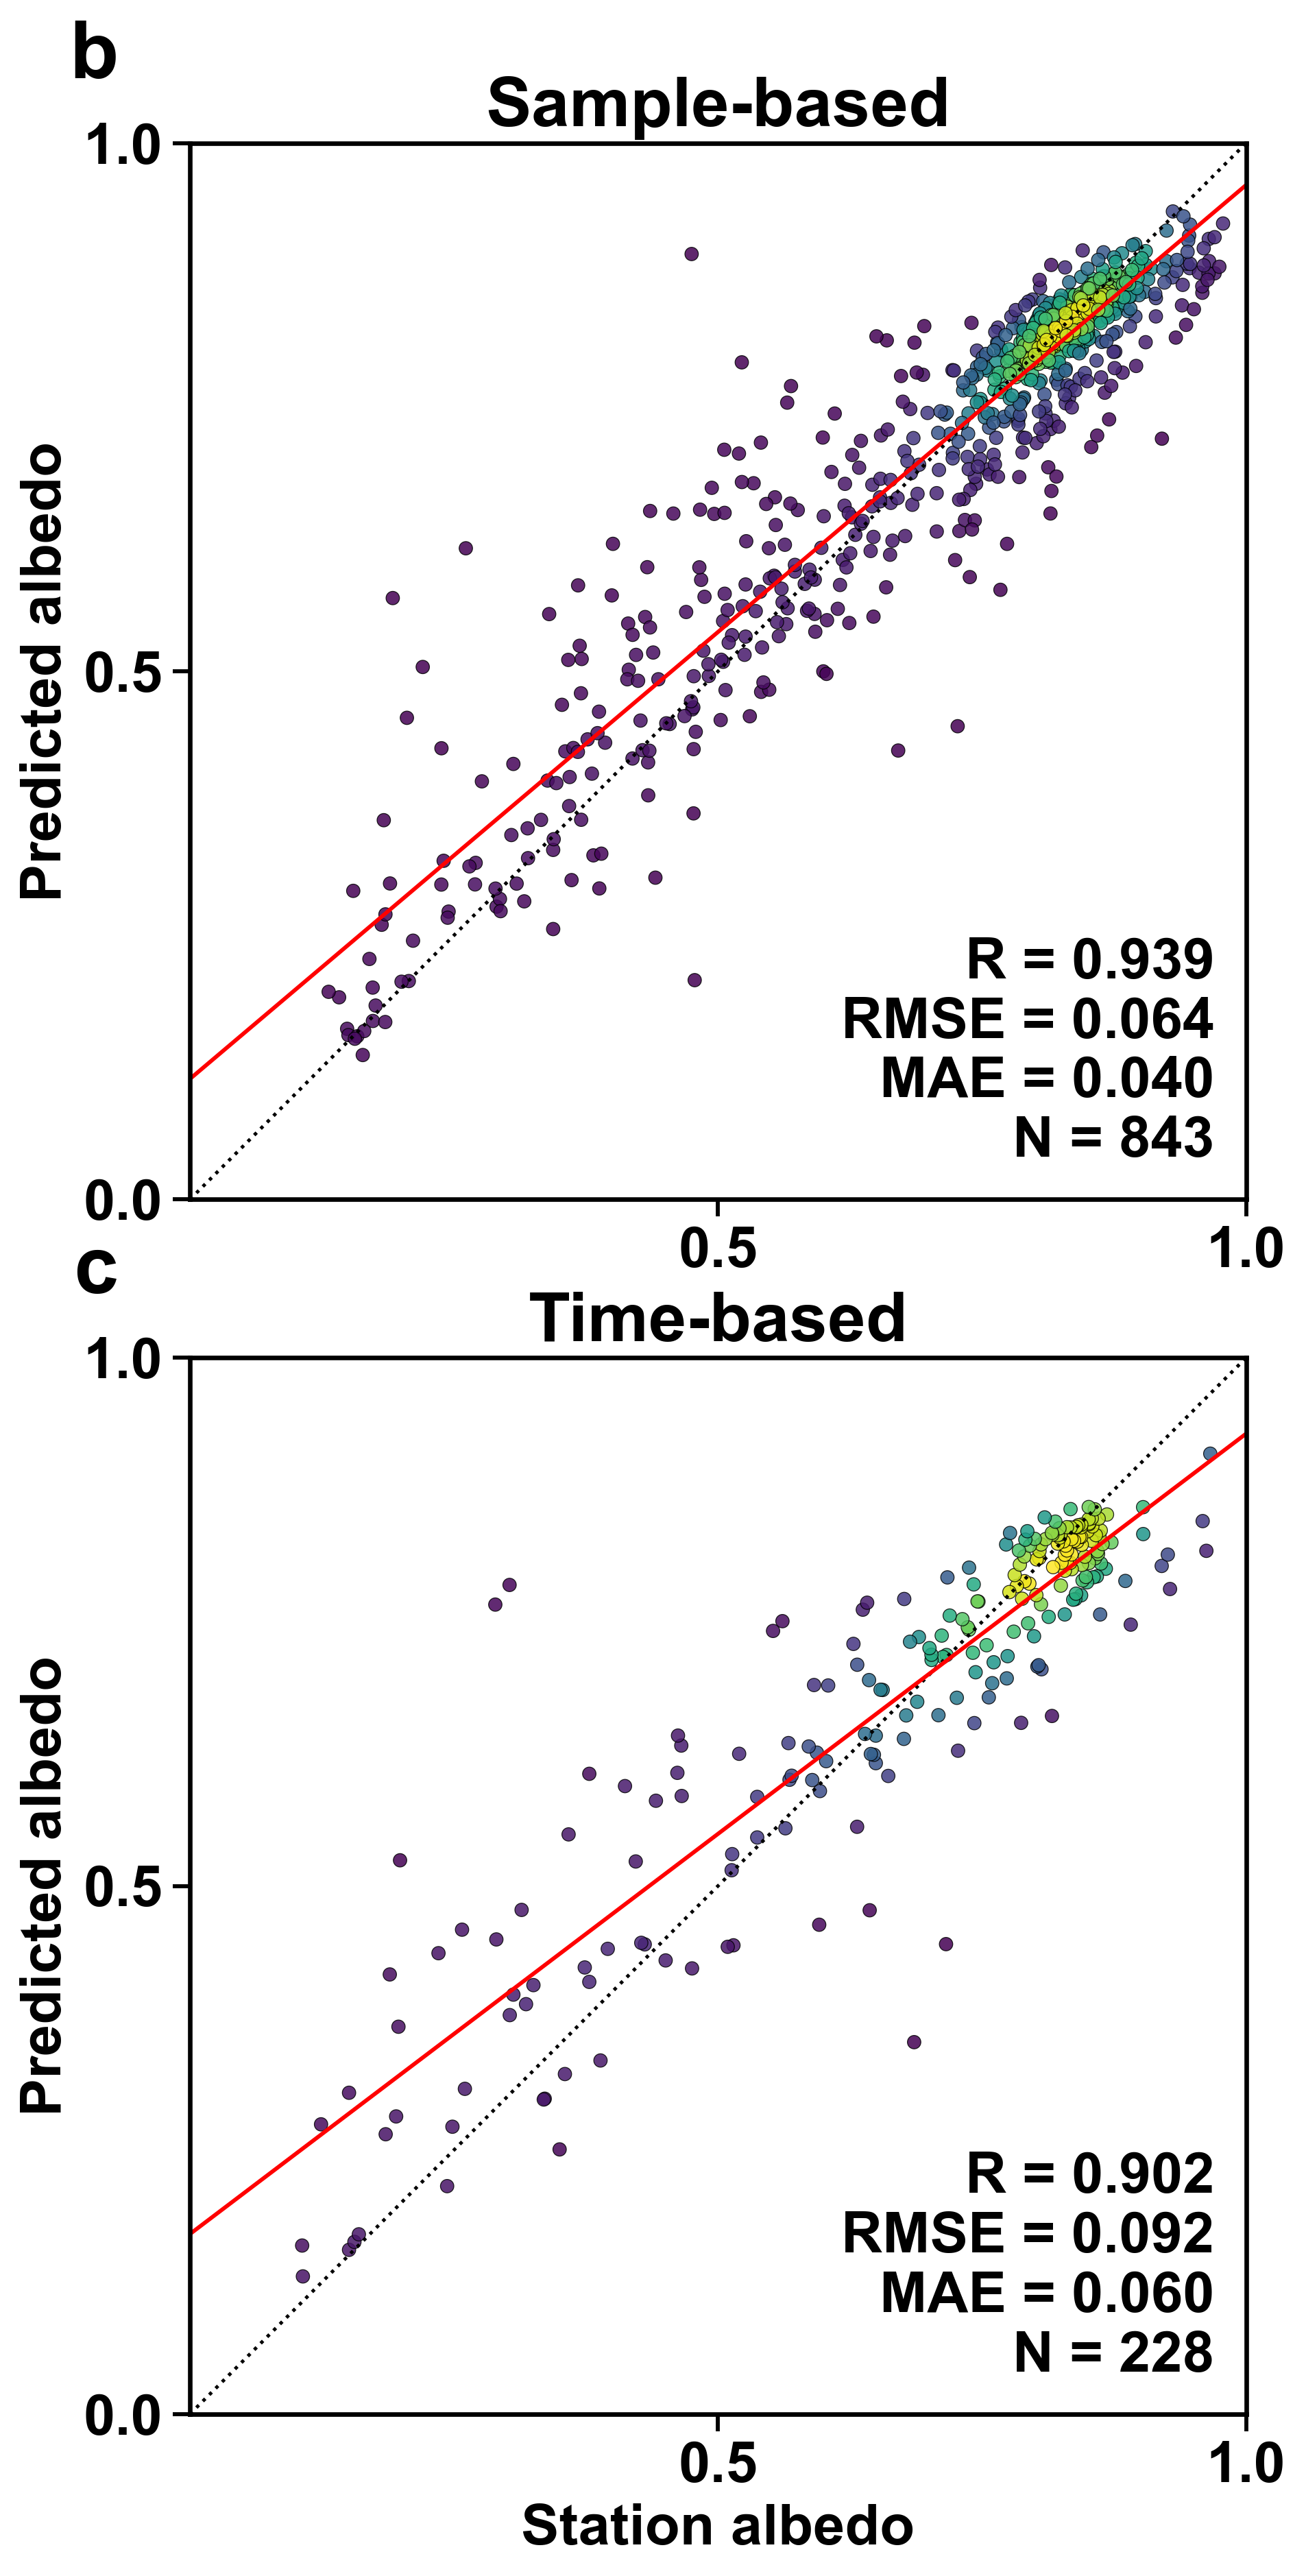

✅ Completed: Saved to
C:\Users\greenlandProject\ERA5LAND\Fig_Validation_2Panel.png


In [ ]:
import os#画竖着的------------样本验证-----------2025年验证------------bc子图------------
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from scipy.stats import pearsonr, gaussian_kde
import xgboost as xgb
import lightgbm as lgb
import catboost

warnings.filterwarnings("ignore")

# ============================================================
# Configuration
# ============================================================
FILE_PATH_MAIN = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
FILE_PATH_TIME = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations_0.1_with_pred_917.xlsx"
OUT_DIR = os.path.dirname(FILE_PATH_MAIN) or "."
OUT_FIG = os.path.join(OUT_DIR, "Fig_Validation_2Panel.png")

TARGET = "albedo"
INPUT_FEATURES = ["longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
                  "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"]
EXCLUDE_STATIONS = ["QAS_M", "MIT", "NUK_K"]

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 20,  # 统一到20号
    "axes.linewidth": 1.6,
    "xtick.major.width": 1.4,
    "ytick.major.width": 1.4,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "figure.dpi": 300
})

# ============================================================
# Utility Functions
# ============================================================
def metrics_r_rmse_mae(y_true, y_pred):
    """Calculate R, RMSE, MAE, N"""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    if len(y_true) < 3:
        return np.nan, np.nan, np.nan, len(y_true)
    r = pearsonr(y_true, y_pred)[0] if np.std(y_true) > 1e-12 and np.std(y_pred) > 1e-12 else np.nan
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(np.mean(np.abs(y_pred - y_true)))
    return float(r), rmse, mae, int(len(y_true))

def add_panel_label(fig, ax, label):
    """Add panel label (b, c) to top-left corner outside the plot frame"""
    # Get axis position in figure coordinates
    bbox = ax.get_position()
    # Place label slightly to the left and above the axis
    fig.text(bbox.x0 - 0.05, bbox.y1 + 0.02, label, 
             fontsize=28, fontweight="bold", ha="right", va="bottom")  # 改为26号

def scatter_density(ax, x, y, title, show_xlabel=True):
    """Create scatter plot with density coloring and statistics"""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    
    # Density calculation (subsample if too many points)
    x_kde, y_kde, use_sample = (x, y, False) if len(x) <= 6000 else (
        x[np.random.RandomState(42).choice(len(x), 6000, replace=False)],
        y[np.random.RandomState(42).choice(len(y), 6000, replace=False)], True)
    
    try:
        z = gaussian_kde(np.vstack([x_kde, y_kde]))(np.vstack([x_kde, y_kde]))
        if not use_sample:
            ax.scatter(x, y, c=z, s=22, edgecolors="black", linewidths=0.3, alpha=0.85)
        else:
            ax.scatter(x, y, s=16, color="0.4", alpha=0.35)
            ax.scatter(x_kde, y_kde, c=z, s=22, edgecolors="black", linewidths=0.3, alpha=0.85)
    except:
        ax.scatter(x, y, s=18, color="0.4", alpha=0.6)
    
    # 1:1 line
    ax.plot([0, 1], [0, 1], linestyle=":", color="black", linewidth=1.2)
    
    # Linear fit line
    if len(x) >= 10:
        a, b = np.polyfit(x, y, 1)
        xx = np.linspace(0, 1, 100)
        ax.plot(xx, a * xx + b, color="red", linewidth=1.4)
    
    # Statistics box
    r, rmse, mae, n = metrics_r_rmse_mae(x, y)
    stats = f"R = {r:.3f}\nRMSE = {rmse:.3f}\nMAE = {mae:.3f}\nN = {n:,}"
    ax.text(0.97, 0.03, stats, transform=ax.transAxes, ha="right", va="bottom", fontsize=20,  # 统一到20号
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=4))
    
    # Axes settings
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0.5, 1.0])  # 删除0.0刻度
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_title(title, loc="center", pad=6)
    ax.set_box_aspect(1)
    if show_xlabel:
        ax.set_xlabel("Station albedo")
    else:
        ax.set_xlabel("")  # b图不显示x轴标签
    ax.set_ylabel("Predicted albedo")

# ============================================================
# Models
# ============================================================
models = {
    'RF': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_estimators=300, n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(n_estimators=300, random_state=42),
    'LGBM': lgb.LGBMRegressor(n_estimators=400, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': catboost.CatBoostRegressor(iterations=500, verbose=0, random_seed=42)
}

def fit_predict_ensemble(X_train, y_train, X_test):
    """Train ensemble of 5 models and return average predictions"""
    preds = [clone(m).fit(X_train, y_train).predict(X_test) for m in models.values()]
    return np.mean(np.column_stack(preds), axis=1)

# ============================================================
# Data Loading
# ============================================================
print(">>> Loading main CSV...")
data = pd.read_csv(FILE_PATH_MAIN)
data = data[~data["station"].isin(EXCLUDE_STATIONS)].copy()
mask = data[TARGET].notna() & ~data[INPUT_FEATURES].isna().any(axis=1)
data_clean = data.loc[mask].copy()

X = data_clean[INPUT_FEATURES].astype(float)
y = data_clean[TARGET].astype(float)

# ============================================================
# b: Sample-based validation
# ============================================================
print(">>> Sample-based split...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_pred_sample = fit_predict_ensemble(X_train, y_train, X_test)

# ============================================================
# c: Time-based validation (Blind-year 2025)
# ============================================================
print(">>> Loading Excel for time-based 2025...")
df_time = pd.read_excel(FILE_PATH_TIME)
df_2025 = df_time[df_time["year"] == 2025].copy()
df_2025 = df_2025.replace([np.inf, -np.inf], np.nan).dropna(subset=["st_albedo", "albedo_pred"])
y_true_time = df_2025["st_albedo"].astype(float).values
y_pred_time = df_2025["albedo_pred"].astype(float).values

# ============================================================
# Plotting: 2 rows, 1 column (b, c)
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(7, 12))
plt.subplots_adjust(hspace=0.15, left=0.18, right=0.95, top=0.97, bottom=0.05)  # hspace从0.35减小到0.15

# b: Sample-based
scatter_density(axes[0], y_test.values, y_pred_sample, "Sample-based", show_xlabel=False)  # 不显示x轴标签
add_panel_label(fig, axes[0], "b")

# c: Time-based
scatter_density(axes[1], y_true_time, y_pred_time, "Time-based", show_xlabel=True)  # 显示x轴标签
add_panel_label(fig, axes[1], "c")

fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"✅ Completed: Saved to\n{OUT_FIG}")

In [96]:
# -*- coding: utf-8 -*-
import os
import numpy as np
import xarray as xr

A_PATH = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature2025.nc"
B_PATH = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\snow3para2025.nc"

B_STD_PATH = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\snow3para2025_std.nc"
OUT_MERGED = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LAND_merged_JJA_2025.nc"

def lon_360_to_180(lon):
    return ((lon + 180) % 360) - 180

def ensure_time_name(ds, target="valid_time"):
    if target in ds.coords or target in ds.dims:
        return ds
    # 常见替代名
    for cand in ["time", "valid_time", "datetime", "date"]:
        if cand in ds.coords or cand in ds.dims:
            if cand != target:
                return ds.rename({cand: target})
            return ds
    # 兜底：找 datetime64 坐标
    for c in ds.coords:
        if np.issubdtype(ds[c].dtype, np.datetime64):
            return ds.rename({c: target})
    raise ValueError("Cannot find time coord in dataset.")

def standardize_snow_to_feature(dsB, dsA):
    """
    把 dsB（snow3para）转换成和 dsA（feature）一致的“标准格式”：
    - coords/dims: valid_time, latitude, longitude（命名一致）
    - 经度统一到 [-180,180] 并排序
    - 按“小范围”（即 dsA 的范围）裁剪到交集
    - 维度顺序统一为 (valid_time, latitude, longitude)
    - 可选：补一个 scalar coord 'number'（与A一致的“坐标名”）
    """
    # 1) 统一时间/经纬度命名
    dsB = ensure_time_name(dsB, "valid_time")

    rename_map = {}
    if "lat" in dsB.coords or "lat" in dsB.dims:
        rename_map["lat"] = "latitude"
    if "lon" in dsB.coords or "lon" in dsB.dims:
        rename_map["lon"] = "longitude"
    if "latitude" not in dsB.coords and "latitude" not in dsB.dims:
        if "y" in dsB.coords or "y" in dsB.dims:
            rename_map["y"] = "latitude"
    if "longitude" not in dsB.coords and "longitude" not in dsB.dims:
        if "x" in dsB.coords or "x" in dsB.dims:
            rename_map["x"] = "longitude"
    if rename_map:
        dsB = dsB.rename(rename_map)

    # 2) 经度统一到 [-180,180]（如果是0-360）
    lon = dsB["longitude"].values
    if np.nanmax(lon) > 180:
        dsB = dsB.assign_coords(longitude=lon_360_to_180(dsB["longitude"]))
    # 排序（非常关键，否则 slice 可能失败）
    dsB = dsB.sortby("longitude")
    dsB = dsB.sortby("latitude")

    # 3) 取小范围：按 dsA 的范围裁剪（交集）
    #    注意 dsA 可能 lat 递减/递增，这里用 min/max 保险
    a_lat = dsA["latitude"].values
    a_lon = dsA["longitude"].values
    lat_min, lat_max = float(np.nanmin(a_lat)), float(np.nanmax(a_lat))
    lon_min, lon_max = float(np.nanmin(a_lon)), float(np.nanmax(a_lon))

    # 确保 slice 方向正确（sortby后是递增）
    dsB = dsB.sel(latitude=slice(lat_min, lat_max), longitude=slice(lon_min, lon_max))

    # 4) 对齐到 dsA 的网格（严格一致），避免“看似同分辨率但点位不完全一致”
    dsB = dsB.interp(
        latitude=dsA["latitude"],
        longitude=dsA["longitude"],
        method="nearest"
    )

    # 5) 维度顺序统一
    #    有些变量可能带其他坐标（如 expver），不影响数据维度
    want_order = [d for d in ["valid_time", "latitude", "longitude"] if d in dsB.dims]
    dsB = dsB.transpose(*want_order)

    # 6) 让“坐标名”更像 dsA（可选但推荐）：补一个 scalar number
    #    dsA 里 number 是 coord 但不是维度；这里给个常数就行
    if "number" in dsA.coords and "number" not in dsB.coords:
        dsB = dsB.assign_coords(number=dsA["number"] if dsA["number"].size == 1 else dsA["number"].isel(number=0))

    # expver：若A有而B没有，也补一个
    if "expver" in dsA.coords and "expver" not in dsB.coords:
        # 给一个标量expver（不作为维度）
        dsB = dsB.assign_coords(expver=dsA["expver"].values[0] if dsA["expver"].size > 0 else 0)

    # 7) 把属性写得干净点（可选）
    dsB.attrs["standardized_like"] = os.path.basename(A_PATH)
    dsB.attrs["lon_convention"] = "[-180, 180]"

    return dsB

def select_JJA(ds, time_name="valid_time"):
    return ds.sel({time_name: ds[time_name].dt.month.isin([6, 7, 8])})

# ====================== RUN ======================
dsA = xr.open_dataset(A_PATH)
dsB = xr.open_dataset(B_PATH)

# 先把 A 也统一一下命名（你之前也在做）
# A: valid_time/latitude/longitude 已有，无需改，但先确保经度排序等
dsA = ensure_time_name(dsA, "valid_time")
dsA = dsA.sortby("longitude")
dsA = dsA.sortby("latitude")

# 1) 标准化 B -> B_STD
dsB_std = standardize_snow_to_feature(dsB, dsA)

# 写出标准化后的 snow 文件
enc_std = {v: {"zlib": True, "complevel": 4} for v in dsB_std.data_vars}
os.makedirs(os.path.dirname(B_STD_PATH), exist_ok=True)
dsB_std.to_netcdf(B_STD_PATH, encoding=enc_std)
print("Saved standardized snow file:", B_STD_PATH)

# 2) 再做 JJA 合并
dsA_jja = select_JJA(dsA, "valid_time")
dsB_jja = select_JJA(dsB_std, "valid_time")

# 若有同名变量冲突：理论上不会（A里没有snowc/sde）
overlap = set(dsA_jja.data_vars).intersection(set(dsB_jja.data_vars))
if overlap:
    dsB_jja = dsB_jja.drop_vars(list(overlap))

dsMerged = xr.merge([dsA_jja, dsB_jja], compat="override", join="exact")

# 最终输出：如果你希望 time/lat/lon 命名和你后续代码一致，也可以这里 rename
dsMerged = dsMerged.rename({"valid_time": "time", "latitude": "lat", "longitude": "lon"})

enc_out = {v: {"zlib": True, "complevel": 4} for v in dsMerged.data_vars}
dsMerged.to_netcdf(OUT_MERGED, encoding=enc_out)

print("Saved merged JJA file:", OUT_MERGED)
print("vars:", list(dsMerged.data_vars))
print("dims:", dict(dsMerged.dims))
print("time months:", np.unique(dsMerged["time"].dt.month.values))
print("lat range:", float(dsMerged["lat"].min()), float(dsMerged["lat"].max()))
print("lon range:", float(dsMerged["lon"].min()), float(dsMerged["lon"].max()))


Saved standardized snow file: C:\Users\greenlandProject\ERA5LAND\ProcessFile\snow3para2025_std.nc
Saved merged JJA file: C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LAND_merged_JJA_2025.nc
vars: ['t2m', 'asn', 'fal', 'slhf', 'ssr', 'str', 'ssrd', 'strd', 'u10', 'v10', 'sp', 'snowc', 'sde']
dims: {'time': 3, 'lat': 301, 'lon': 701}
time months: [6 7 8]
lat range: 55.0 85.0
lon range: -80.0 -10.0


In [112]:
import pandas as pd
import numpy as np
import pickle
import joblib
import os

CSV_IN  = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\2025678allfeature.csv"
CSV_OUT = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\2025678allfeature_with_albedo.csv"

# 3个可用base
XGB_PATH = r"C:\Users\11823\era5land\saved_models_917\XGB_917.pkl"
LGB_PATH = r"C:\Users\11823\era5land\saved_models_917\LGBM_917.pkl"
CAT_PATH = r"C:\Users\11823\era5land\saved_models_917\CatBoost_917.pkl"

# 5维的meta（任意一个都行：它们n_features_in_=5）
META_PATH = r"C:\Users\11823\era5land\saved_models_917\meta_model_917.pkl"

# base模型要求的15维输入（你已验证过）
FEATURE_COLS = [
    "longitude", "latitude", "altitude_last_valid",
    "sp", "ssrd", "str", "strd", "t2m", "u10", "v10",
    "snowc", "sde", "asn", "year", "month"
]

# meta期望5列：按常见顺序假定 [RF, XGB, GBDT, LGBM, CAT]
# 你缺 RF/GBDT -> 用0补齐
def build_meta_matrix(xgb_pred, lgb_pred, cat_pred, n):
    Z = np.zeros((n, 5), dtype=np.float32)
    Z[:, 1] = xgb_pred.astype(np.float32)  # XGB
    Z[:, 3] = lgb_pred.astype(np.float32)  # LGBM
    Z[:, 4] = cat_pred.astype(np.float32)  # CAT
    # Z[:,0]=RF 缺失 -> 0
    # Z[:,2]=GBDT 缺失 -> 0
    return Z

# ---------------- load csv ----------------
df = pd.read_csv(CSV_IN)
missing = [c for c in FEATURE_COLS if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

X = df[FEATURE_COLS].to_numpy()

# 只对“输入15列全是有限值”的像元做预测（最稳）
valid = np.isfinite(X).all(axis=1)

# ---------------- load models ----------------
with open(XGB_PATH, "rb") as f:
    xgb = pickle.load(f)
with open(LGB_PATH, "rb") as f:
    lgb = pickle.load(f)
with open(CAT_PATH, "rb") as f:
    cat = pickle.load(f)

meta = joblib.load(META_PATH)  # Ridge

# ---------------- predict base ----------------
y = np.full(len(df), np.nan, dtype=np.float32)

if valid.any():
    Xv = X[valid]

    xgb_p = xgb.predict(Xv)
    lgb_p = lgb.predict(Xv)
    cat_p = cat.predict(Xv)

    Z = build_meta_matrix(xgb_p, lgb_p, cat_p, n=Xv.shape[0])

    # ---------------- predict meta ----------------
    y[valid] = meta.predict(Z).astype(np.float32)

df["outputalbedo"] = y
os.makedirs(os.path.dirname(CSV_OUT), exist_ok=True)
df.to_csv(CSV_OUT, index=False)

print("DONE")
print("Saved:", CSV_OUT)
print("Valid predictions:", int(valid.sum()), "/", len(df))
print("Albedo range:", float(np.nanmin(y)), float(np.nanmax(y)))


DONE
Saved: C:\Users\greenlandProject\ERA5LAND\ProcessFile\2025678allfeature_with_albedo.csv
Valid predictions: 65821 / 146268
Albedo range: 0.1360711008310318 0.7787896990776062


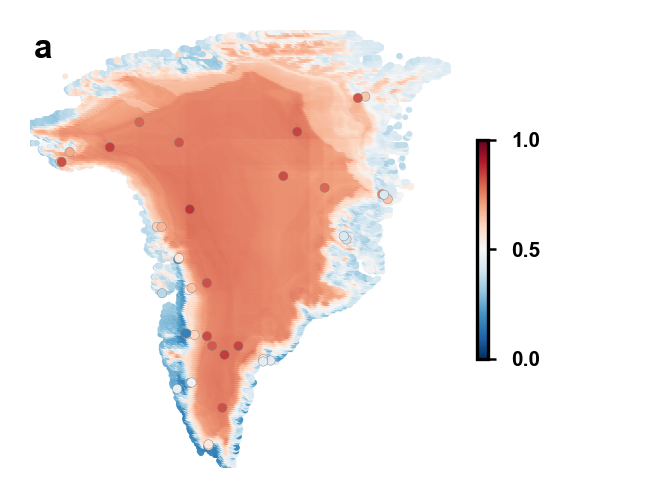

In [ ]:
import pandas as pd#2025的站点和--------------模型预测-----站点画图-------------------
import matplotlib.pyplot as plt

CSV_GRID = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\2025678allfeature_with_albedo.csv"
CSV_ST   = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\albedo_2025_all_stations.csv"

VMIN, VMAX = 0.0, 1.0
CMAP = "RdBu_r"

# -------- read grid (background) --------
df = pd.read_csv(CSV_GRID, usecols=["latitude", "longitude", "outputalbedo"])
df = df.dropna(subset=["outputalbedo"])

# -------- read stations (2025 JJA) --------
st = pd.read_csv(
    CSV_ST,
    usecols=["station", "year", "month", "st_albedo", "longitude", "latitude"]
)
st = st.dropna(subset=["st_albedo", "longitude", "latitude"])
st = st[(st["year"] == 2025) & (st["month"].isin([6, 7, 8]))]

# 每站点取 JJA 均值
st_jja = (
    st.groupby("station", as_index=False)
      .agg(latitude=("latitude", "mean"),
           longitude=("longitude", "mean"),
           st_albedo=("st_albedo", "mean"))
)

# -------- plot --------
fig, ax = plt.subplots(figsize=(2.5, 2))

# background scatter
sc = ax.scatter(
    df["longitude"], df["latitude"],
    c=df["outputalbedo"],
    s=2,
    cmap=CMAP,
    vmin=VMIN, vmax=VMAX,
    linewidths=0
)

# overlay stations
if len(st_jja) > 0:
    ax.scatter(
        st_jja["longitude"], st_jja["latitude"],
        c=st_jja["st_albedo"],
        s=5,
        cmap=CMAP,
        vmin=VMIN, vmax=VMAX,
        marker="o",
        edgecolors="grey",
        linewidths=0.1,
        zorder=5
    )

# -------- colorbar --------
cbar = plt.colorbar(sc, ax=ax, shrink=0.5)
cbar.set_ticks([0.0, 0.5, 1.0])
cbar.ax.tick_params(
    labelsize=5,
    length=2.0,   # 缩短刻度线
    width=0.6
)
cbar.set_label(" ")

# -------- panel label --------
ax.text(
    0.01, 0.99, "a",
    transform=ax.transAxes,
    ha="left", va="top",
    fontsize=8,
    fontweight="bold"
)

# extent
ax.set_xlim(df["longitude"].min(), df["longitude"].max())
ax.set_ylim(df["latitude"].min(), df["latitude"].max())

ax.axis("off")
plt.tight_layout()
plt.show()


>>> Loading main CSV...
>>> Site-based LOSO for TAS_L...
>>> Site-based LOSO for ZAC_L...
>>> Site-based LOSO for KAN_B...


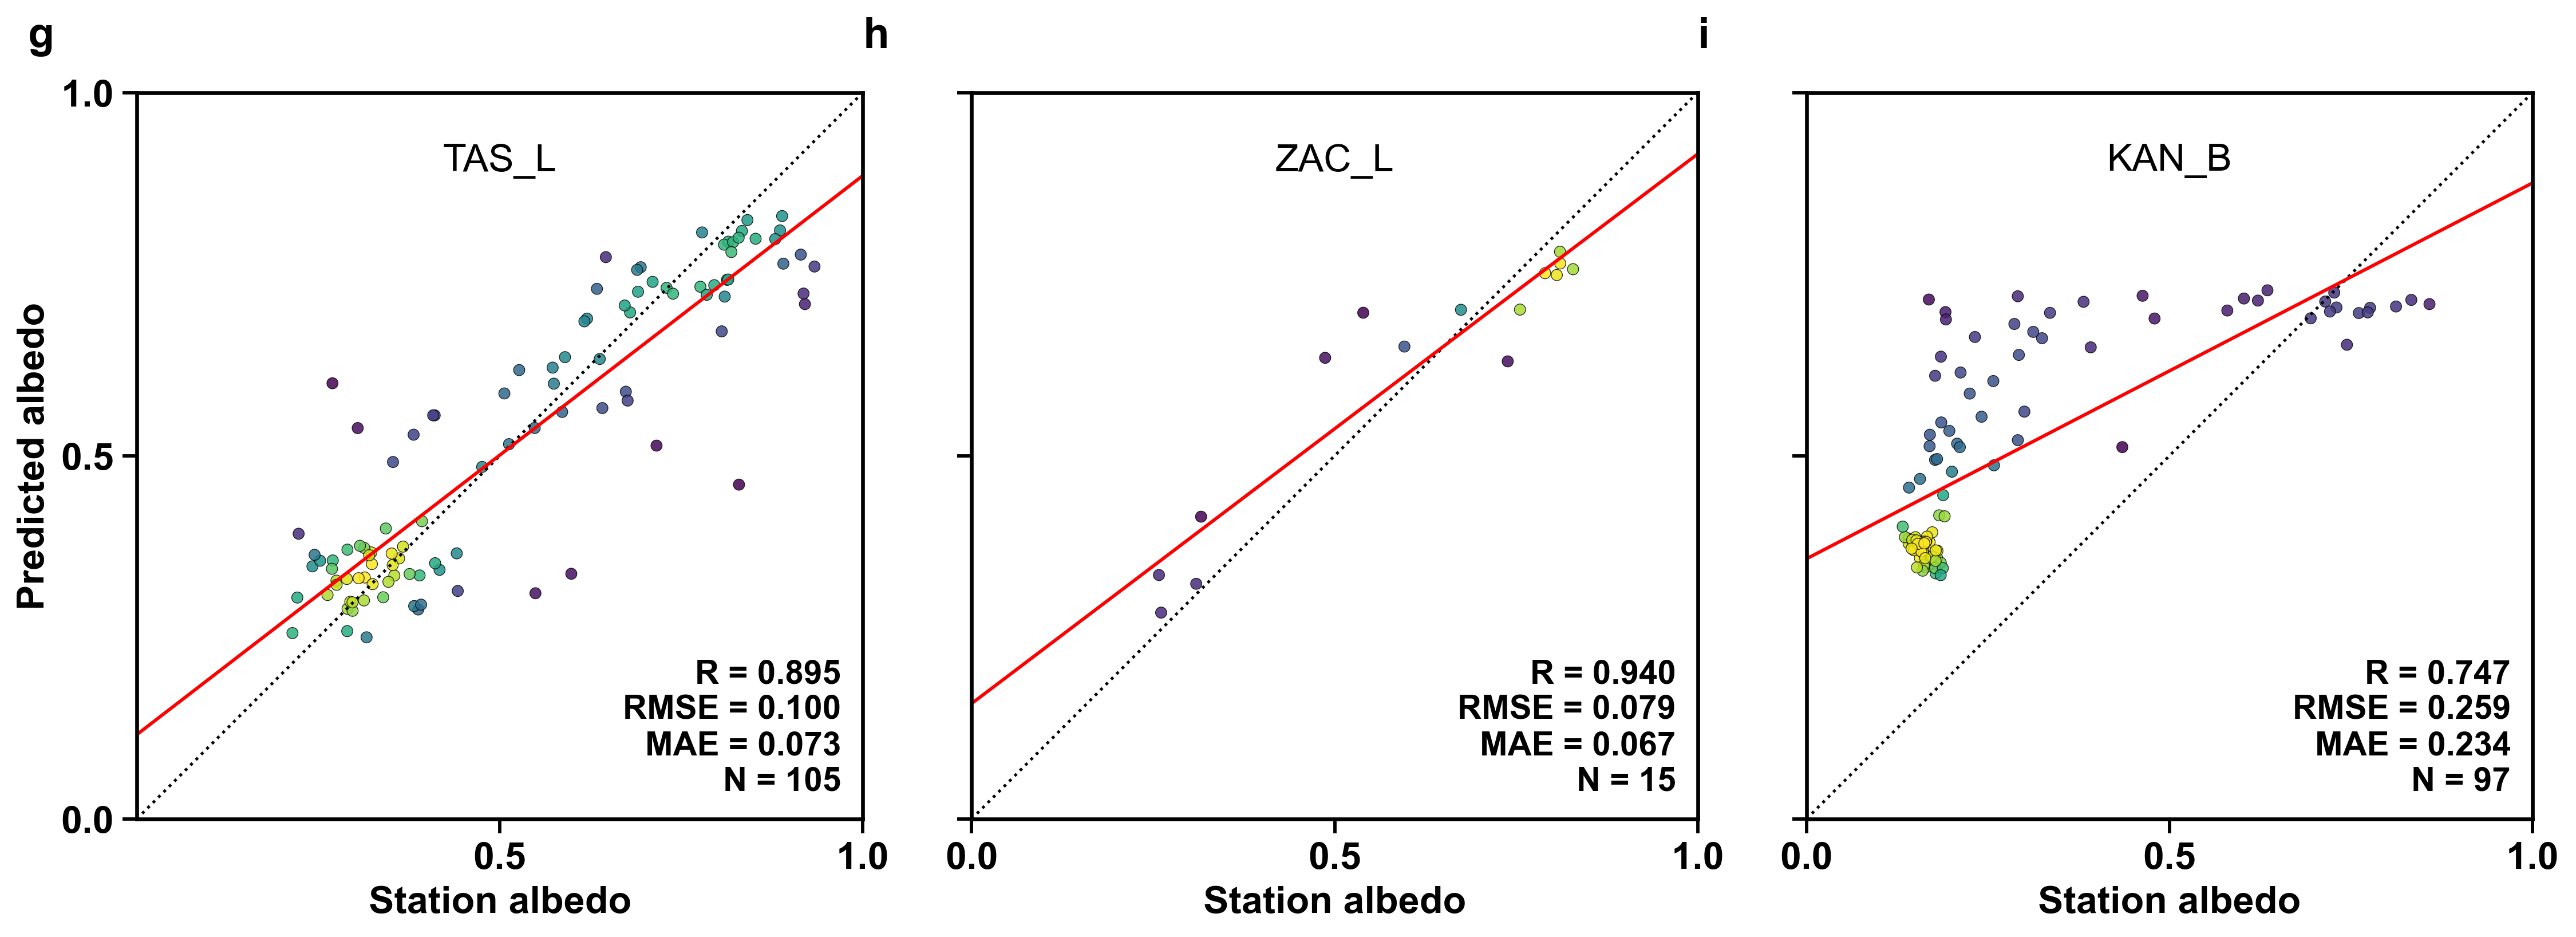

✅ Completed: Saved to
C:\Users\greenlandProject\ERA5LAND\Fig_Three_Stations_LOSO.png


In [146]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from scipy.stats import pearsonr, gaussian_kde
import xgboost as xgb
import lightgbm as lgb
import catboost

warnings.filterwarnings("ignore")

# ============================================================
# Configuration
# ============================================================
FILE_PATH_MAIN = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
OUT_DIR = os.path.dirname(FILE_PATH_MAIN) or "."
OUT_FIG = os.path.join(OUT_DIR, "Fig_Three_Stations_LOSO.png")

TARGET = "albedo"
STATIONS_LOSO = ["TAS_L", "ZAC_L", "KAN_B"]  # Three stations for LOSO
INPUT_FEATURES = ["longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
                  "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"]
EXCLUDE_STATIONS = ["QAS_M", "MIT", "NUK_K"]

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 16,
    "axes.linewidth": 1.6,
    "xtick.major.width": 1.4,
    "ytick.major.width": 1.4,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "figure.dpi": 300
})

# ============================================================
# Utility Functions
# ============================================================
def metrics_r_rmse_mae(y_true, y_pred):
    """Calculate R, RMSE, MAE, N"""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    if len(y_true) < 3:
        return np.nan, np.nan, np.nan, len(y_true)
    r = pearsonr(y_true, y_pred)[0] if np.std(y_true) > 1e-12 and np.std(y_pred) > 1e-12 else np.nan
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(np.mean(np.abs(y_pred - y_true)))
    return float(r), rmse, mae, int(len(y_true))

def add_panel_label(ax, label):
    """Add panel label (g, h, i) outside top-left corner"""
    ax.text(-0.15, 1.05, label, transform=ax.transAxes, ha="left", va="bottom",
            fontsize=18, fontweight="bold")

def scatter_density(ax, x, y, station_name, show_ylabel, is_first):
    """Create scatter plot with density coloring and statistics"""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    
    # Density calculation (subsample if too many points)
    x_kde, y_kde, use_sample = (x, y, False) if len(x) <= 6000 else (
        x[np.random.RandomState(42).choice(len(x), 6000, replace=False)],
        y[np.random.RandomState(42).choice(len(y), 6000, replace=False)], True)
    
    try:
        z = gaussian_kde(np.vstack([x_kde, y_kde]))(np.vstack([x_kde, y_kde]))
        if not use_sample:
            ax.scatter(x, y, c=z, s=22, edgecolors="black", linewidths=0.3, alpha=0.85)
        else:
            ax.scatter(x, y, s=16, color="0.4", alpha=0.35)
            ax.scatter(x_kde, y_kde, c=z, s=22, edgecolors="black", linewidths=0.3, alpha=0.85)
    except:
        ax.scatter(x, y, s=18, color="0.4", alpha=0.6)
    
    # 1:1 line
    ax.plot([0, 1], [0, 1], linestyle=":", color="black", linewidth=1.2)
    
    # Linear fit line
    if len(x) >= 10:
        a, b = np.polyfit(x, y, 1)
        xx = np.linspace(0, 1, 100)
        ax.plot(xx, a * xx + b, color="red", linewidth=1.4)
    
    # Statistics box
    r, rmse, mae, n = metrics_r_rmse_mae(x, y)
    stats = f"R = {r:.3f}\nRMSE = {rmse:.3f}\nMAE = {mae:.3f}\nN = {n:,}"
    ax.text(0.97, 0.03, stats, transform=ax.transAxes, ha="right", va="bottom", fontsize=14,
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=4))
    
    # Station name (like "Time-based" position in reference image)
    ax.text(0.5, 0.93, station_name, transform=ax.transAxes, ha="center", va="top",
            fontsize=16, fontweight="normal")
    
    # Axes settings
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    
    # Special handling for first plot (g): remove 0.0 from x-axis
    if is_first:
        ax.set_xticks([0.5, 1.0])
    else:
        ax.set_xticks([0.0, 0.5, 1.0])
    
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_box_aspect(1)
    ax.set_xlabel("Station albedo")
    ax.set_ylabel("Predicted albedo" if show_ylabel else "")
    if not show_ylabel:
        ax.set_yticklabels([])

# ============================================================
# Models
# ============================================================
models = {
    'RF': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_estimators=300, n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(n_estimators=300, random_state=42),
    'LGBM': lgb.LGBMRegressor(n_estimators=400, n_jobs=-1, random_state=42, verbose=-1),
    'CatBoost': catboost.CatBoostRegressor(iterations=500, verbose=0, random_seed=42)
}

def fit_predict_ensemble(X_train, y_train, X_test):
    """Train ensemble of 5 models and return average predictions"""
    preds = [clone(m).fit(X_train, y_train).predict(X_test) for m in models.values()]
    return np.mean(np.column_stack(preds), axis=1)

# ============================================================
# Data Loading
# ============================================================
print(">>> Loading main CSV...")
data = pd.read_csv(FILE_PATH_MAIN)
data = data[~data["station"].isin(EXCLUDE_STATIONS)].copy()
mask = data[TARGET].notna() & ~data[INPUT_FEATURES].isna().any(axis=1)
data_clean = data.loc[mask].copy()

X = data_clean[INPUT_FEATURES].astype(float)
y = data_clean[TARGET].astype(float)
stations = data_clean["station"].astype(str)

# ============================================================
# LOSO for three stations
# ============================================================
results = {}
for station in STATIONS_LOSO:
    print(f">>> Site-based LOSO for {station}...")
    train_mask = stations != station
    test_mask = stations == station
    
    if test_mask.sum() == 0:
        print(f"⚠ Warning: No samples found for station {station}")
        continue
    
    y_pred = fit_predict_ensemble(X[train_mask], y[train_mask], X[test_mask])
    y_true = y[test_mask].values
    results[station] = (y_true, y_pred)

# ============================================================
# Plotting: 1 row, 3 columns (g, h, i)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
plt.subplots_adjust(wspace=0.15)  # Smaller spacing between subplots

panel_labels = ['g', 'h', 'i']

for idx, (station, label) in enumerate(zip(STATIONS_LOSO, panel_labels)):
    if station not in results:
        print(f"⚠ Skipping {station} - no data")
        continue
    
    y_true, y_pred = results[station]
    show_ylabel = (idx == 0)  # Only first plot shows y-label
    is_first = (idx == 0)  # First plot is 'g'
    
    scatter_density(axes[idx], y_true, y_pred, station, show_ylabel, is_first)
    add_panel_label(axes[idx], label)

fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"✅ Completed: Saved to\n{OUT_FIG}")

>>> Loading CSV...


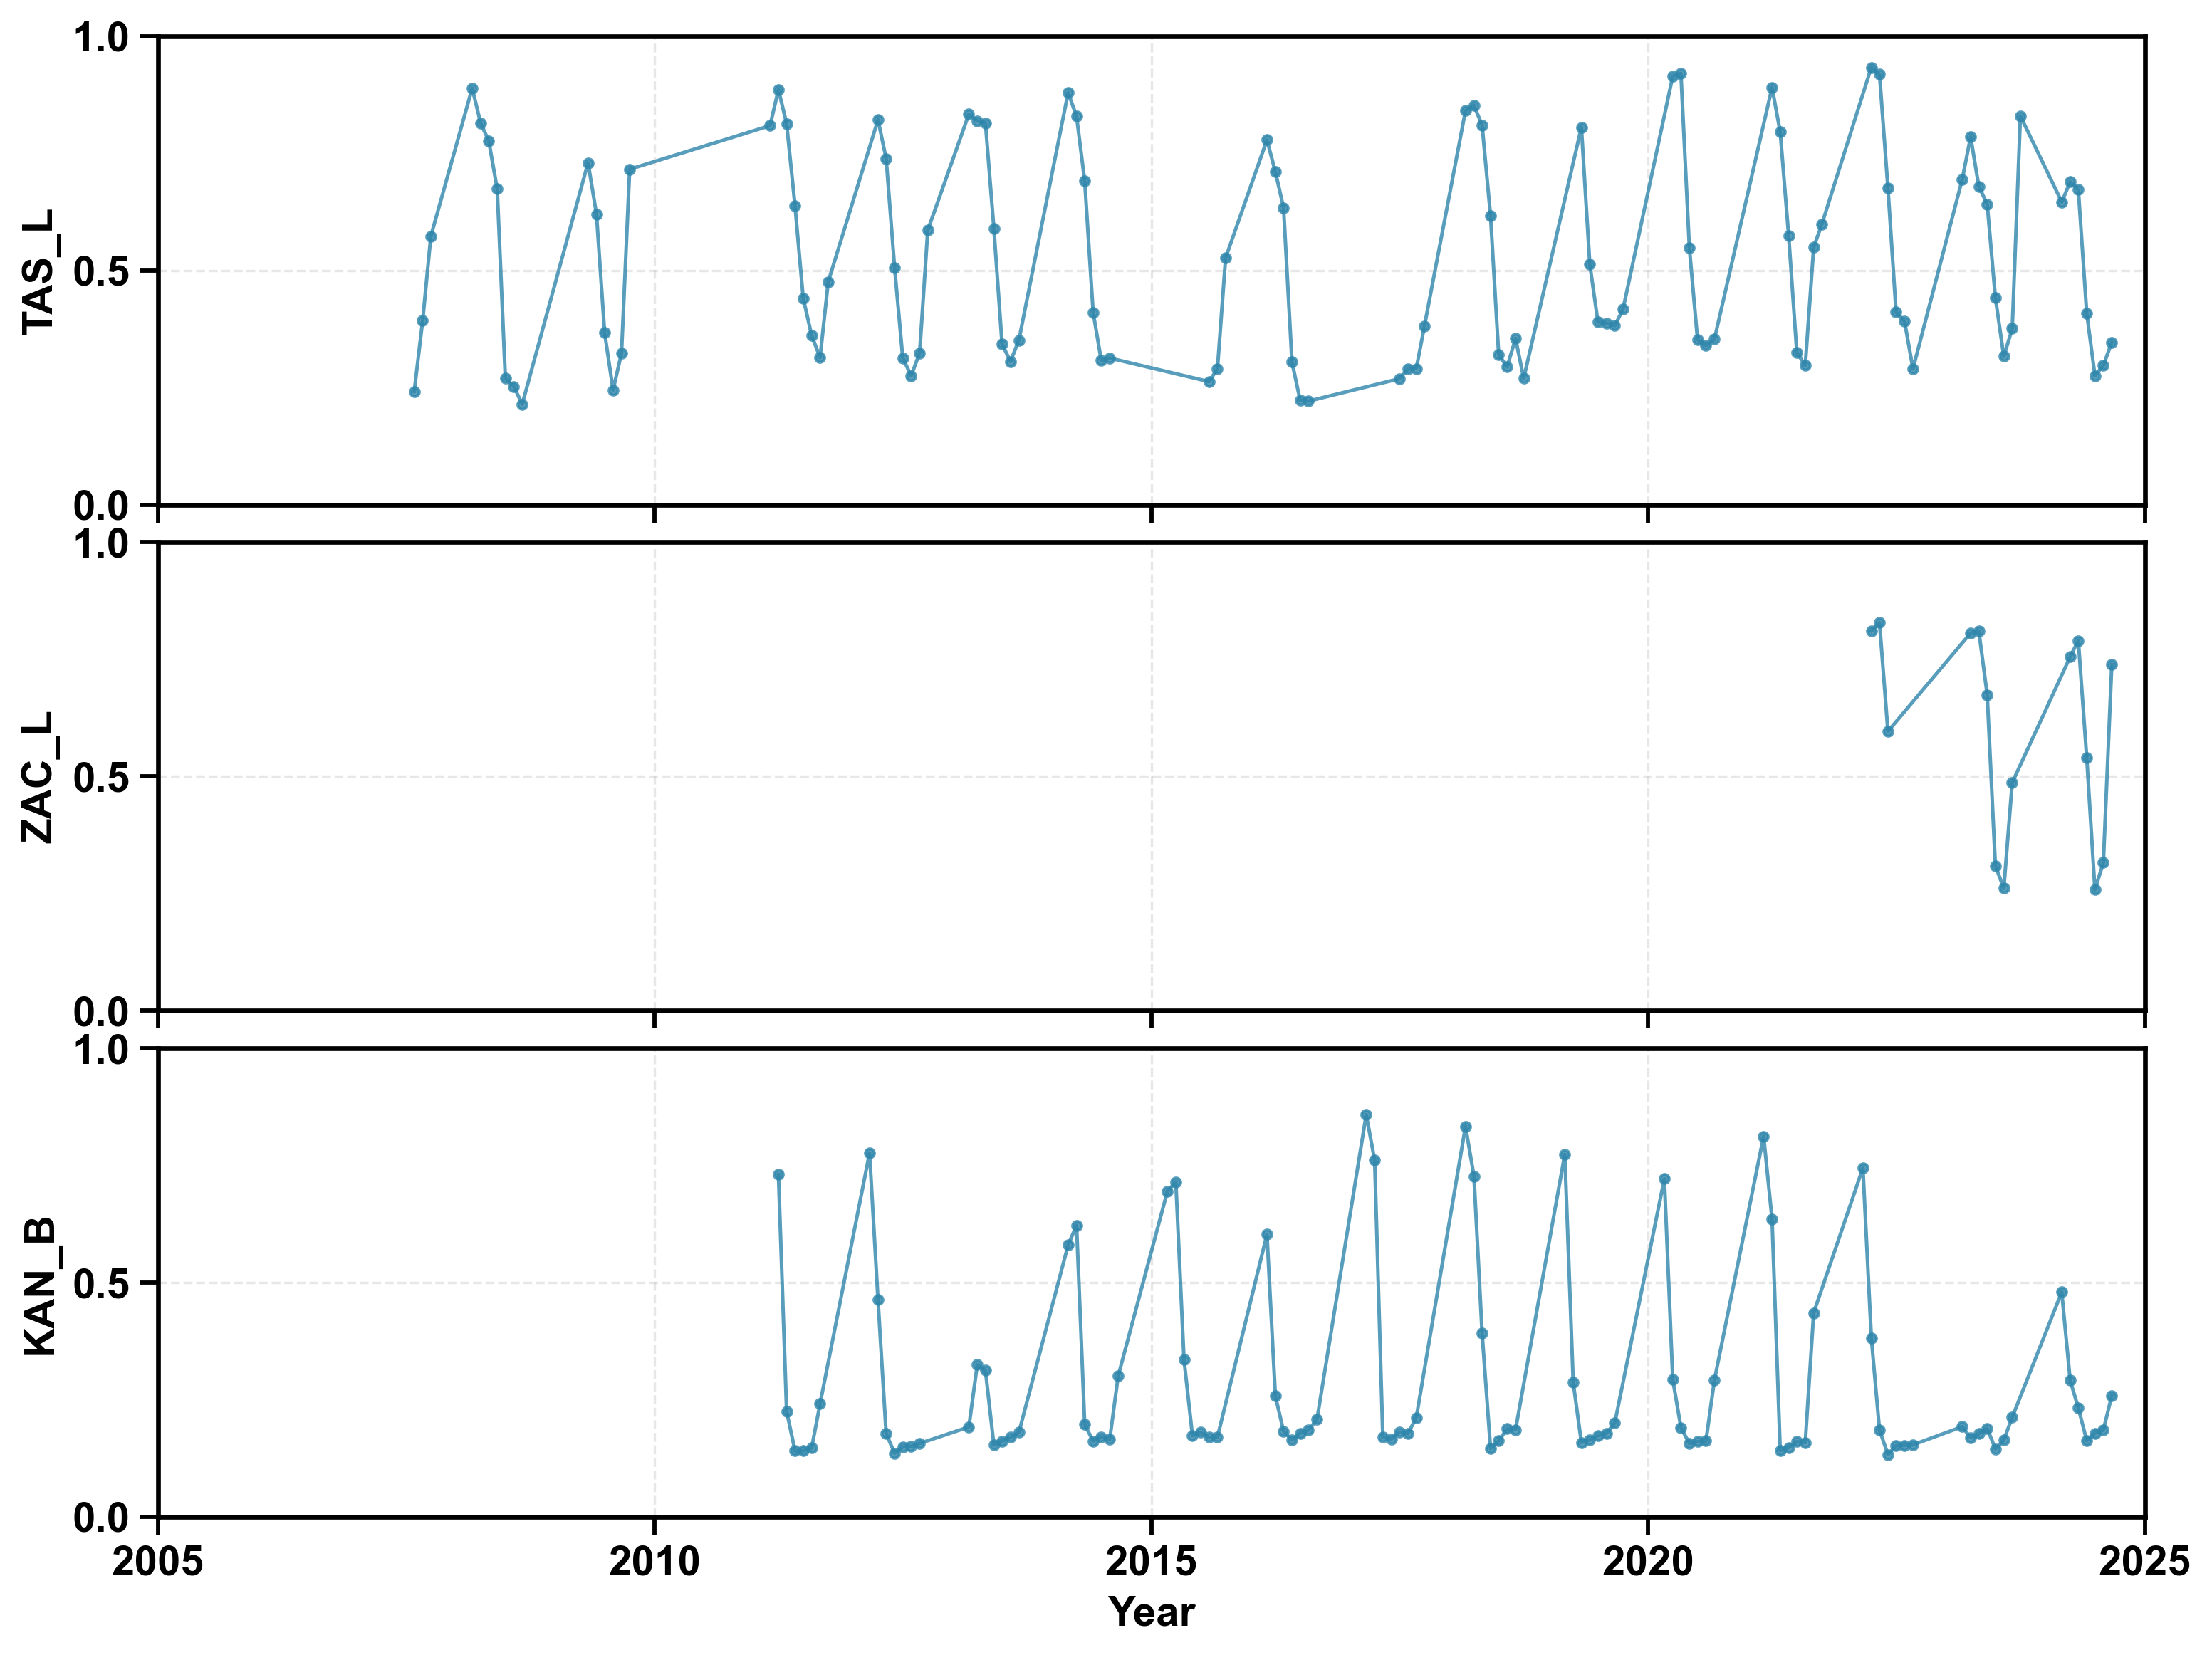

✅ Saved to: C:\Users\greenlandProject\ERA5LAND\Fig_Three_Stations_Timeseries.png


In [158]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore")

# ============================================================
# Configuration
# ============================================================
FILE_PATH = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
OUT_DIR = os.path.dirname(FILE_PATH) or "."
OUT_FIG = os.path.join(OUT_DIR, "Fig_Three_Stations_Timeseries.png")

STATIONS = ["TAS_L", "ZAC_L", "KAN_B"]

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 14,
    "axes.linewidth": 1.6,
    "xtick.major.width": 1.4,
    "ytick.major.width": 1.4,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "figure.dpi": 300
})

# ============================================================
# Data Loading
# ============================================================
print(">>> Loading CSV...")
data = pd.read_csv(FILE_PATH)

# ---- date column ----
if 'year' in data.columns and 'month' in data.columns:
    data['date'] = pd.to_datetime(data[['year', 'month']].assign(day=1))
    date_col = 'date'
elif 'date' in data.columns:
    data['date'] = pd.to_datetime(data['date'])
    date_col = 'date'
else:
    raise ValueError("No date information found")

# ---- station / albedo ----
station_col = 'station'
albedo_col = [c for c in data.columns if 'albedo' in c.lower()][0]

# ============================================================
# Plotting
# ============================================================
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
plt.subplots_adjust(hspace=0.08)

for idx, (station, ax) in enumerate(zip(STATIONS, axes)):

    st = data[data[station_col] == station].copy()
    st = st[st[albedo_col].notna()].sort_values(date_col)

    ax.plot(
        st[date_col],
        st[albedo_col],
        color="#2E86AB",
        linewidth=1.2,
        marker="o",
        markersize=3,
        alpha=0.8
    )

    ax.set_ylabel(station, fontweight="bold")
    ax.set_ylim(0, 1)
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.grid(True, alpha=0.3, linestyle="--", linewidth=0.8)

# ============================================================
# X-axis: hard stop at 2025 (NO tail)
# ============================================================
axes[-1].set_xlabel("Year", fontweight="bold")

for ax in axes:
    ax.set_xlim(pd.Timestamp("2005-01-01"), pd.Timestamp("2025-01-01"))
    ax.margins(x=0)  # <<< 关键：去掉右侧多余空间
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=0, ha="center")

# ============================================================
# Save
# ============================================================
fig.align_ylabels(axes)
fig.savefig(OUT_FIG, bbox_inches="tight", facecolor="white")
plt.show()

print(f"✅ Saved to: {OUT_FIG}")
